# RepSeq UCB Analysis - MIPT seminar

**Как работать с ноутбуком.** Сначала выполняем блок настройки путей и загрузки подготовленных репертуаров, затем разбираем качество данных и отдельные метрики TCR. Код анализирует **β-цепь TCR (TRB)**. Один клоносет соответствует одному образцу, а клонотипу соответствует последовательность рецептора с заданным правилом определения совпадения.

Файлы результатов сохраняются в `outputs/repseq/`; каталог создаётся кодом при выполнении. Предполагается, что данные уже подключены к `data/ucb_figshare/` (например, символьной ссылкой на общую папку с клоносетами и метаданными).

## Imports

**Назначение библиотек.** `pandas` — таблицы и метаданные; `os`/`pathlib` — пути; `repseq.clonosets` — поиск таблиц клонотипов; `repseq.clone_filter` — фильтрация; `repseq.stats` — вычисление метрик; `repseq.plot` — построение графиков; `repseq.beta` — сравнение образцов; `repseq.clustering` — поиск близких последовательностей. `CategoricalDtype` задаёт порядок групп на графиках.

In [ ]:
!pip install repseq


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 14.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [repseq]


In [ ]:
%pip install logomaker

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.2/13.2 MB 88.3 MB/s  0:00:00


In [ ]:
# Импортируем библиотеки, которые потребуются для таблиц, расчёта метрик и графиков.
import pandas as pd
from pandas.api.types import CategoricalDtype
import os

from repseq import clonosets as cl
from repseq import io as repseqio
from repseq import clone_filter as clf
from repseq import stats
from repseq import plot as rsplot
from repseq import clustering
from repseq import beta

**Относительные пути.** Ноутбук ищет корень проекта по наличию `environment.yml` и папки `notebooks`, поэтому не требует фиксированного домашнего каталога пользователя. Для корректной работы открывайте его из проекта или любой его вложенной папки. `WORKING_DIR` — место для **новых результатов**, а не для входных FASTQ/клоносетов.

## WORKING DIR

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path
import os

PROJECT_ROOT = Path('/content/drive/MyDrive/Colab Notebooks/ImmuneSem')

WORKING_DIR = str(PROJECT_ROOT / 'outputs' / 'repseq')

os.makedirs(WORKING_DIR, exist_ok=True)

print("Проект найден:", PROJECT_ROOT.exists())
print("Данные найдены:", (PROJECT_ROOT / 'data').exists())
print("Папка результатов:", WORKING_DIR)

Проект найден: True
Данные найдены: True
Папка результатов: /content/drive/MyDrive/Colab Notebooks/ImmuneSem/outputs/repseq


**Что представляет собой входной датасет.** Здесь используются уже обработанные данные RepSeq: файлы `*.clonotypes.TRB.txt` с клонотипами, а не исходные FASTQ. В исходной схеме подготовки данных MiGEC учитывал UMI, затем MiXCR собирал клонотипы. Поэтому счётчики с историческим названием *reads* в этих таблицах отражают результаты обработки на уровне молекулярных наблюдений, а не просто число исходных FASTQ-прочтений.

Обратите внимание на различие: **число клонотипов** — сколько различных последовательностей обнаружено; **число наблюдений** — сколько раз эти последовательности зарегистрированы. Именно второе используется при анализе частот и даунсэмплировании.

## Read clonosets

In [ ]:
# Указываем папку с готовыми клоносетами и таблицей метаданных UCB.
clonosets_ucb_dir = str(PROJECT_ROOT / "data" / "ucb_figshare")


In [ ]:
# Находим все клоносеты в каталоге и собираем таблицу ссылок на файлы;
# # show_offtarget=False исключает нерелевантные цепи по правилу библиотеки.
clonosets = cl.find_all_mixcr_clonosets(clonosets_ucb_dir, # <- put path (or a list of paths) to your folder(s) with clonosets
                                        show_offtarget=False,
                                        offtarget_threshold=0.01
                                       )
clonosets

,sample_id,chain,filename
0,c5_nTreg_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...
1,UCB5_nCD4_TRB_2,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...
2,UCB3_nCD8_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...
3,UCB2_nCD4_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...
4,UCB6_nTreg_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...
...,...,...,...
82,UCB5_nCD8_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...
83,a5_nTreg_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...
84,a3_nTreg_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...
85,o6_nTreg_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...


The dataset also contains metadata table, which can read as a pandas DataFrame

**Метаданные связывают образцы с экспериментом.** `sample_id` — имя образца и ключ объединения; `experimental_group` — возрастная/экспериментальная группа; `donor_id` — донор; `subset` — отсортированная клеточная популяция. Для групп `preterm`, `term`, `late` источник обозначается как UCB (пуповинная кровь), для остальных — PB (периферическая кровь).

Заданный порядок категорий нужен для осмысленного расположения групп на графиках; это **не** числовая переменная и **не** результат статистического теста. Проверяйте количество образцов в каждой группе, прежде чем сравнивать её с другими.

## Create metadata

In [ ]:
# Задаём порядок экспериментальных групп и клеточных популяций для графиков.
# # Затем читаем метаданные и добавляем источник материала: UCB или PB.
# Define the custom ordered type
exp_group_order = CategoricalDtype(categories=['preterm', 'term', 'late', 'children', 'adults', 'older_adults'], ordered=True)
subset_order = CategoricalDtype(categories=["nCD4", "nTreg", "nCD8"], ordered=True)

metadata = pd.read_csv(os.path.join(clonosets_ucb_dir, "ucb_figshare_TRB_metadata.csv"))[["sample_id", "experimental_group", "donor_id", "subset"]]
metadata["experimental_group"] = metadata["experimental_group"].astype(exp_group_order)
metadata["subset"] = metadata["subset"].astype(subset_order)
metadata["source"] = metadata["experimental_group"].apply(lambda x: "UCB" if x in ['preterm', 'term', 'late'] else "PB")
# metadata["sample_id"] = metadata["sample_id"].apply(lambda x: x.split("_TRB")[0])
metadata.tail()

,sample_id,experimental_group,donor_id,subset,source
82,a6_nCD8_TRB_1,adults,a6,nCD8,PB
83,a4_nCD8_TRB_1,adults,a4,nCD8,PB
84,a12_nCD8_TRB_1,adults,a12,nCD8,PB
85,a14_nTreg_TRB_1,adults,a14,nTreg,PB
86,a16_nTreg_TRB_1,adults,a16,nTreg,PB


**Почему выделяем только nTreg.** В одном датасете есть несколько отсортированных популяций. Их репертуары могут различаться по биологии и глубине секвенирования. На занятии работаем с `nTreg` (наивные регуляторные T-клетки), чтобы сравнение возрастных групп не смешивалось с различиями клеточных типов. Для домашнего задания эту строку отбора можно заменить на `nCD4` или `nCD8`.

## Subset clonosets

In [ ]:
# Объединяем пути к клоносетам с метаданными по общим столбцам и оставляем nCD4
clonosets_cd4 = clonosets.merge(metadata).query("subset == 'nCD4'").reset_index(drop=True)
clonosets_cd4

,sample_id,chain,filename,experimental_group,donor_id,subset,source
0,UCB5_nCD4_TRB_2,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,preterm,UCB5,nCD4,UCB
1,UCB2_nCD4_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,term,UCB2,nCD4,UCB
2,a7_mnCD4_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,adults,a7,nCD4,PB
3,UCB3_nCD4_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,term,UCB3,nCD4,UCB
4,UCB9_nCD4_TRB_2,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,late,UCB9,nCD4,UCB
5,a11_mnCD4_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,adults,a11,nCD4,PB
6,a15_mnCD4_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,adults,a15,nCD4,PB
7,c1_mnCD4_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,children,c1,nCD4,PB
8,c2_mnCD4_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,children,c2,nCD4,PB
9,UCB7_nCD4_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,late,UCB7,nCD4,UCB


**Сначала оценим объём и качество.** В `clonoset_stats` важно различать `clones` и `clones_func` (общее число клонотипов и продуктивных), `reads` и `reads_func` (число наблюдений), а также `clones_nonfunc` и синглтоны.

**Важное свойство конкретного набора:** в сохранённой таблице статистики колонки `umi`, `umi_func` и т. п. имеют значения `NaN`. Поэтому некоторые функции `repseq` выдают предупреждение и **используют `reads` вместо отдельного столбца UMI**. В этих исторически обработанных MiGEC/MiXCR-данных не следует автоматически отождествлять `reads` с сырыми ридами FASTQ. Это важно для объяснения `by_umi=True` ниже.

## Have a look at clonosets contents

In [ ]:
# Для каждого образца рассчитываем число клонов, функциональных клонов и наблюдений.
clonoset_stats_cd4 = stats.calc_clonoset_stats(clonosets_cd4, cpu=2)
clonoset_stats_cd4

Using 2 cores
CalcClonosetStats |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,clones,clones_func,clones_func_singletons,clones_func_non_singletons,clones_nonfunc,clones_nonfunc_freq,reads,reads_func,reads_nonfunc,reads_nonfunc_freq,umi,umi_func,umi_nonfunc,umi_nonfunc_freq,reads_per_umi
0,UCB5_nCD4_TRB_2,TRB,49366,46447,21731,24716,2919,0.059130,104347,100848,3499,0.033532,NaN,NaN,NaN,NaN,NaN
1,UCB2_nCD4_TRB_1,TRB,81956,78511,44542,33969,3445,0.042035,139476,135541,3935,0.028213,NaN,NaN,NaN,NaN,NaN
2,a7_mnCD4_TRB_1,TRB,15395,14760,10071,4689,635,0.041247,22940,22220,720,0.031386,NaN,NaN,NaN,NaN,NaN
3,UCB3_nCD4_TRB_1,TRB,38736,36701,25164,11537,2035,0.052535,55515,53298,2217,0.039935,NaN,NaN,NaN,NaN,NaN
4,UCB9_nCD4_TRB_2,TRB,115560,110597,57166,53431,4963,0.042947,213888,208078,5810,0.027164,NaN,NaN,NaN,NaN,NaN
5,a11_mnCD4_TRB_1,TRB,27477,26285,16492,9793,1192,0.043382,43923,42563,1360,0.030963,NaN,NaN,NaN,NaN,NaN
6,a15_mnCD4_TRB_1,TRB,30937,30199,23876,6323,738,0.023855,39413,38612,801,0.020323,NaN,NaN,NaN,NaN,NaN
7,c1_mnCD4_TRB_1,TRB,34691,33429,25394,8035,1262,0.036378,45792,44444,1348,0.029437,NaN,NaN,NaN,NaN,NaN
8,c2_mnCD4_TRB_1,TRB,4667,4508,3481,1027,159,0.034069,6084,5912,172,0.028271,NaN,NaN,NaN,NaN,NaN
9,UCB7_nCD4_TRB_1,TRB,44002,41850,24999,16851,2152,0.048907,71461,68876,2585,0.036174,NaN,NaN,NaN,NaN,NaN


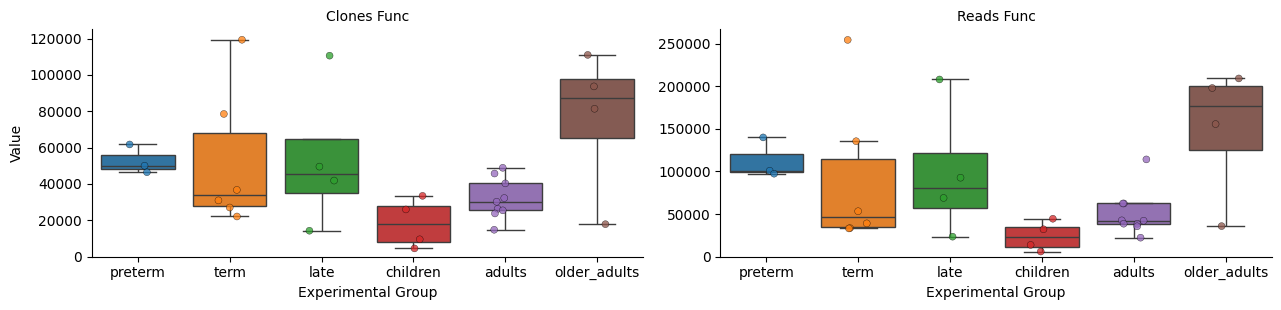

In [ ]:
# Сравниваем объём функциональной части репертуаров между экспериментальными группами.
rsplot.clonoset_stats(clonoset_stats_cd4, metadata=metadata, group="experimental_group", properties=["clones_func", "reads_func"], aspect=2)

In [ ]:
# Сортируем образцы по числу функциональных наблюдений: это помогает выбрать downsample.
clonoset_stats_cd4.sort_values(by="reads_func")

,sample_id,chain,clones,clones_func,clones_func_singletons,clones_func_non_singletons,clones_nonfunc,clones_nonfunc_freq,reads,reads_func,reads_nonfunc,reads_nonfunc_freq,umi,umi_func,umi_nonfunc,umi_nonfunc_freq,reads_per_umi
8,c2_mnCD4_TRB_1,TRB,4667,4508,3481,1027,159,0.034069,6084,5912,172,0.028271,NaN,NaN,NaN,NaN,NaN
20,c4_mnCD4_TRB_1,TRB,9912,9515,6818,2697,397,0.040052,14155,13695,460,0.032497,NaN,NaN,NaN,NaN,NaN
2,a7_mnCD4_TRB_1,TRB,15395,14760,10071,4689,635,0.041247,22940,22220,720,0.031386,NaN,NaN,NaN,NaN,NaN
25,UCB4_nCD4_TRB_1,TRB,15004,14235,8453,5782,769,0.051253,24297,23395,902,0.037124,NaN,NaN,NaN,NaN,NaN
16,c5_mnCD4_TRB_1,TRB,26673,25952,21374,4578,721,0.027031,32840,32077,763,0.023234,NaN,NaN,NaN,NaN,NaN
24,UCB6_nCD4_TRB_1,TRB,23056,22069,14572,7497,987,0.042809,34149,33053,1096,0.032095,NaN,NaN,NaN,NaN,NaN
11,UCB12_mnCD4_TRB_1,TRB,28150,27005,22218,4787,1145,0.040675,34663,33459,1204,0.034734,NaN,NaN,NaN,NaN,NaN
19,a9_mnCD4_TRB_1,TRB,24536,23743,16874,6869,793,0.032320,36490,35572,918,0.025158,NaN,NaN,NaN,NaN,NaN
10,o5_mnCD4_TRB_1,TRB,19077,17835,9580,8255,1242,0.065105,37447,35797,1650,0.044062,NaN,NaN,NaN,NaN,NaN
14,a1_mnCD4_TRB_1,TRB,26520,25444,17282,8162,1076,0.040573,39766,38486,1280,0.032188,NaN,NaN,NaN,NaN,NaN


In [ ]:
depths = clonoset_stats_cd4["reads_func"]

print(depths.describe())

count        30.000000
mean      81121.233333
std       66861.282891
min        5912.000000
25%       35628.250000
50%       48871.000000
75%      110831.250000
max      254528.000000
Name: reads_func, dtype: float64


In [ ]:
clonoset_stats_cd4.merge(metadata).groupby("experimental_group").size()

/tmp/ipykernel_438/530957239.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  clonoset_stats_cd4.merge(metadata).groupby("experimental_group").size()


,0
experimental_group,
preterm,3
term,6
late,4
children,4
adults,9
older_adults,4


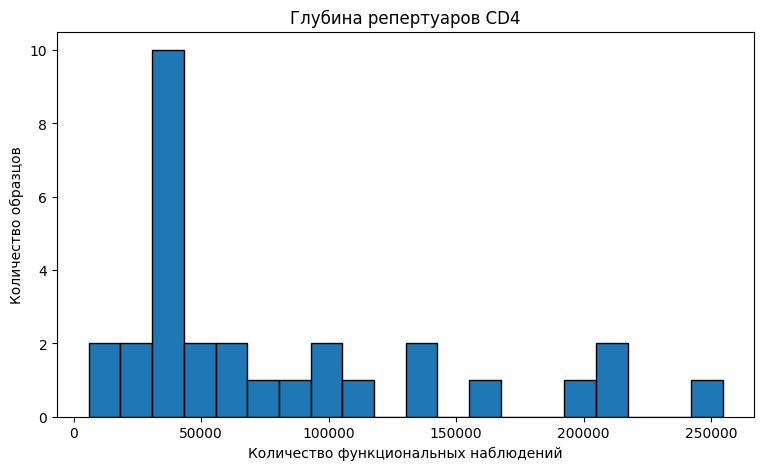

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.hist(depths.dropna(), bins=20, edgecolor="black")
plt.xlabel("Количество функциональных наблюдений")
plt.ylabel("Количество образцов")
plt.title("Глубина репертуаров CD4")
plt.show()

In [ ]:
for depth in [1000, 2000, 3000, 4500, 5000, 10000]:
    n = (depths >= depth).sum()
    print(f"Глубина {depth}: {n} из {len(depths)} образцов")

Глубина 1000: 30 из 30 образцов
Глубина 2000: 30 из 30 образцов
Глубина 3000: 30 из 30 образцов
Глубина 4500: 30 из 30 образцов
Глубина 5000: 30 из 30 образцов
Глубина 10000: 29 из 30 образцов


**Обоснование выбора глубины даунсэмплирования**

Для дальнейшего анализа была выбрана глубина даунсэмплирования 5000 наблюдений. Это позволяет сохранить все 30 образцов и проводить сравнение репертуаров при одинаковой глубине (при увеличении порога до 10 000 один образец был бы исключён из анализа) Таким образом, значение 5000 было выбрано как компромисс между сохранением всех образцов и стандартизацией глубины

In [ ]:
# Заранее определяем фильтр продуктивных клонов и фильтр с равной глубиной 4500.
# # Внимание: отдельная колонка UMI в этих клоносетах отсутствует; см. примечание выше. (для CD4 взяла 5000 глубину)
func_filter = clf.Filter(functionality="f", by_umi=True)
downsample_filter = clf.Filter(functionality="f", downsample=5000, by_umi=True, seed=100)

**Один фильтр — одинаковые правила для всех образцов.** `clf.Filter` хранит настройки, которые передаются в вычислительные функции. Фильтры нужны, чтобы исключать нефункциональные последовательности, ограничивать число клонотипов или выравнивать число наблюдений между образцами.

- `functionality='f'` оставляет продуктивные последовательности (в рамке считывания, без стоп-кодона в соответствующем участке). Непродуктивные транскрипты могут реже наблюдаться из-за отбора и, в части случаев, NMD; их доля в данных **не** обязана быть равна доле непроизводительных перестроек на уровне ДНК.
- `top` оставляет наиболее многочисленные клонотипы; `downsample` выбирает заданное **число наблюдений** случайным образом. Это разные процедуры: первая обогащает частые клоны, вторая стандартизирует глубину.
- `seed` фиксирует случайность и делает сравнение воспроизводимым. `by_umi=True` предпочтителен при наличии UMI-счётчиков; когда отдельного поля нет, проверяйте сообщения библиотеки о фактически выбранном счётчике.

**Вопрос:** почему нельзя напрямую сравнить число обнаруженных клонотипов в образцах с существенно разной глубиной?

При разной глубине секвенирования обнаруживается разное количество клонотипов: чем больше наблюдений - тем выше вероятность выявить редкие клонотипы. Поэтому для корректного сравнения необходимо выровнять глубину образцов с помощью даунсэмплирования

## Filters

**`Filter` - is a special object, that may be used as a setup for Postanalysis.** You can easily create or change one and put it as an argument to other functions for individual clonoset or multi-clonoset metrics

Here is a basic default filter with all possible options:

In [ ]:
# Просматриваем все настройки объекта Filter. Это пример конфигурации, не запуск анализа.
clf.Filter(name="default_filter",         # <- name of the filter
           functionality="a",             # <- functional clonotypes = clonotypes without STOP codons or out-of-frames (OOFs) in the CDR3 region, "a" = all clonotypes, "f" = leave only functional, "n" = leave only non-functional
           downsample=None,               # <- randomly downsample to this count value
           top=None,                      # <- take top-N clonotypes
           by_umi=False,                  # <- False = count by read-counts, True = count by UMI counts, if such a column exists
           mix_tails=False,               # <- True = mix all clonotypes with same counts randomly
           count_threshold=None,          # <- set minimal count value for clonotypes, others will be filtered out
           unweight=False,                # <- set count=1 to all clonotypes
           seed=None,                     # <- set seed for random processes, like downsampling and mixing tails for reproducibility
           recount_fractions=True,        # <- should you normalize all fractions to sum to 1 after filtering procedures?
           white_list=[],                 # <- a list of clonotypes, that should be left in the clonoset (the syntax for the list is below)
           black_list=[],                 # <- a list of clonotypes, that should be filtered out
           pool_clonoset_by="",           # <- combine clonotypes into one by CDR3, V or J equlity
           convert=True,                  # <- convert=False preserves all the columns of the original clonoset table. Otherwise the clonoset will be converted into VDJtools-like format for simplicity
           ignore_small_clonosets=False   # <- =True suppreses the warnings when clonoset is smaller than the given downsample or top values.
          )

Here are some examples of useful filters:

### Functional

functionality options: `a` (default) - any. `f` - only functional, `n` - only non-functional

In [ ]:
# Оставляем функциональные клонотипы и используем счётчики UMI, если они доступны.
func_filter = clf.Filter(functionality="f", by_umi=True)
func_filter

**`top=4000` не означает 4000 наблюдений.** Это выбор 4000 клонотипов с наибольшими счётчиками. Если несколько клонотипов имеют одинаковый счётчик около границы отсечения, `mix_tails=True` перемешивает их для уменьшения зависимости результата от порядка строк. `seed=100` делает такое перемешивание повторяемым.

### Top

top clonotypes by count. Recommended to mix the tails and specify the seed

In [ ]:
# Сохраняем 4000 наиболее частых клонов; смешиваем равные по счётчику хвосты случайно.
top_filter = clf.Filter(functionality="f", top=4000, by_umi=True, mix_tails=True, seed=100)
top_filter

**Зачем нужен даунсэмпл.** Сравнение разнообразия без контроля глубины может дать ложное преимущество глубоко прочитанному образцу: чем больше наблюдений, тем больше редких клонотипов можно обнаружить. `downsample=4500` задаёт общую глубину для примера с nTreg, но **не является универсальным порогом** для остальных клеточных популяций. Его выбирают после изучения распределения размеров образцов; слишком высокий порог может привести к исключению малых образцов.

### Downsample

Take a random sample by counts (UMI or reads). Seed is recommended to use for reproducibility.

Usually used for Diversity metrics, Convergence and other procedures, which require sample normalization

In [ ]:
# Случайно приводим образцы к глубине 4500 наблюдений с фиксированным seed.
downsample_filter = clf.Filter(functionality="f", downsample=5000, by_umi=True, seed=100)
downsample_filter

# Analysis

**Свойства CDR3.** CDR3 — наиболее вариабельная область рецептора, в формировании которой участвуют V(D)J-рекомбинация, обрезание концов и вставки нуклеотидов. Помимо длины можно описывать физико-химические свойства аминокислотной последовательности (заряд, гидрофобность и др.). Графики ниже сравнивают распределения **по образцам**, сгруппированным по `experimental_group`; отдельные точки — это не независимые T-клетки.

Найденное различие не обязательно означает различие антигенной специфичности: это косвенные характеристики репертуара.

## CDR3 properties

Calculates different properties for CDR3 region. In this case we passed `func_filter` to make calculations only for 'functional' clonotypes

In [ ]:
from pathlib import Path
import repseq
import repseq.stats as repseq_stats

# Ищем таблицу свойств аминокислот
repseq_dir = Path(repseq.__file__).resolve().parent

files = list(repseq_dir.rglob("aa_property_table.txt"))

print("Найденные файлы:", files)
print("Старый путь:", repseq_stats.AA_PROPS_PATH)

Найденные файлы: [PosixPath('/usr/local/lib/python3.13/dist-packages/repseq/resourses/aa_property_table.txt')]
Старый путь: /root/soft/repseq/repseq/resourses/aa_property_table.txt


In [ ]:
if files:
    repseq_stats.AA_PROPS_PATH = str(files[0])
    print("Новый путь:", repseq_stats.AA_PROPS_PATH)
else:
    print("Файл не найден в установленной библиотеке repseq")

Новый путь: /usr/local/lib/python3.13/dist-packages/repseq/resourses/aa_property_table.txt


In [ ]:
# Считаем длину, вставки и свойства аминокислот CDR3 для функциональных клонов.
cdr3_properties = stats.calc_cdr3_properties(clonosets_cd4, cl_filter=func_filter, cpu=2)
cdr3_properties

Using 2 cores
CalcCDR3aaProperties |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,mean_cdr3nt_len,mean_insert_size,zero_insert_freq,mean_frequency,cdr3_5_hydropathy,cdr3_full_hydropathy,cdr3_5_charge,cdr3_full_charge,...,cdr3_5_turn,cdr3_full_turn,cdr3_5_alpha,cdr3_full_alpha,cdr3_5_beta,cdr3_full_beta,cdr3_5_core,cdr3_full_core,cdr3_5_disorder,cdr3_full_disorder
0,UCB5_nCD4_TRB_2,TRB,40.406860,2.940197,0.289555,0.000022,-4.757558,-3.512079,-0.016431,-0.298449,...,5.831050,13.955976,4.535339,13.279585,4.810224,13.226433,0.293906,0.728101,2.298687,2.174837
1,UCB2_nCD4_TRB_1,TRB,42.690057,6.190702,0.054721,0.000013,-3.920459,-3.055040,0.032662,-0.281288,...,5.866770,14.818899,4.487542,13.967770,4.809110,13.964593,0.289836,0.767684,2.391158,2.556784
2,a7_mnCD4_TRB_1,TRB,43.286409,7.347210,0.023897,0.000068,-3.895945,-3.816256,0.053015,-0.397750,...,5.899163,15.074565,4.475954,14.196801,4.793958,14.102293,0.288995,0.777674,2.463546,2.845095
3,UCB3_nCD4_TRB_1,TRB,42.068839,5.514147,0.087020,0.000027,-4.112897,-3.699036,-0.012421,-0.392979,...,5.845735,14.570026,4.523018,13.829758,4.802395,13.743637,0.290124,0.756167,2.373785,2.518631
4,UCB9_nCD4_TRB_2,TRB,42.846534,6.214199,0.057007,0.000009,-3.711005,-3.331997,0.148127,-0.295697,...,5.777485,14.752849,4.520114,14.107939,4.837992,14.029632,0.290647,0.770879,2.268798,2.512817
5,a11_mnCD4_TRB_1,TRB,44.108381,7.936776,0.018537,0.000038,-3.553835,-3.524956,0.134060,-0.259827,...,5.857520,15.311865,4.473015,14.475639,4.822125,14.384579,0.289283,0.793819,2.413951,2.926133
6,a15_mnCD4_TRB_1,TRB,43.523775,7.415001,0.022066,0.000033,-3.826243,-3.487615,0.114032,-0.272221,...,5.840369,15.073617,4.493124,14.305103,4.814939,14.201070,0.289315,0.782280,2.401585,2.741868
7,c1_mnCD4_TRB_1,TRB,43.141166,7.305328,0.020633,0.000030,-3.584009,-2.817438,0.182679,-0.137206,...,5.780803,14.878958,4.497077,14.139802,4.848155,14.141306,0.289706,0.775997,2.249505,2.473112
8,c2_mnCD4_TRB_1,TRB,42.990528,6.952977,0.023173,0.000222,-4.271972,-3.328535,0.112145,-0.172530,...,5.862618,14.922075,4.489398,14.099733,4.793567,14.009540,0.288798,0.770355,2.458728,2.739005
9,UCB7_nCD4_TRB_1,TRB,42.445714,6.293557,0.047869,0.000024,-4.064085,-3.611341,0.088521,-0.292773,...,5.853409,14.718116,4.499951,13.924331,4.801558,13.862349,0.289997,0.763203,2.394956,2.599193


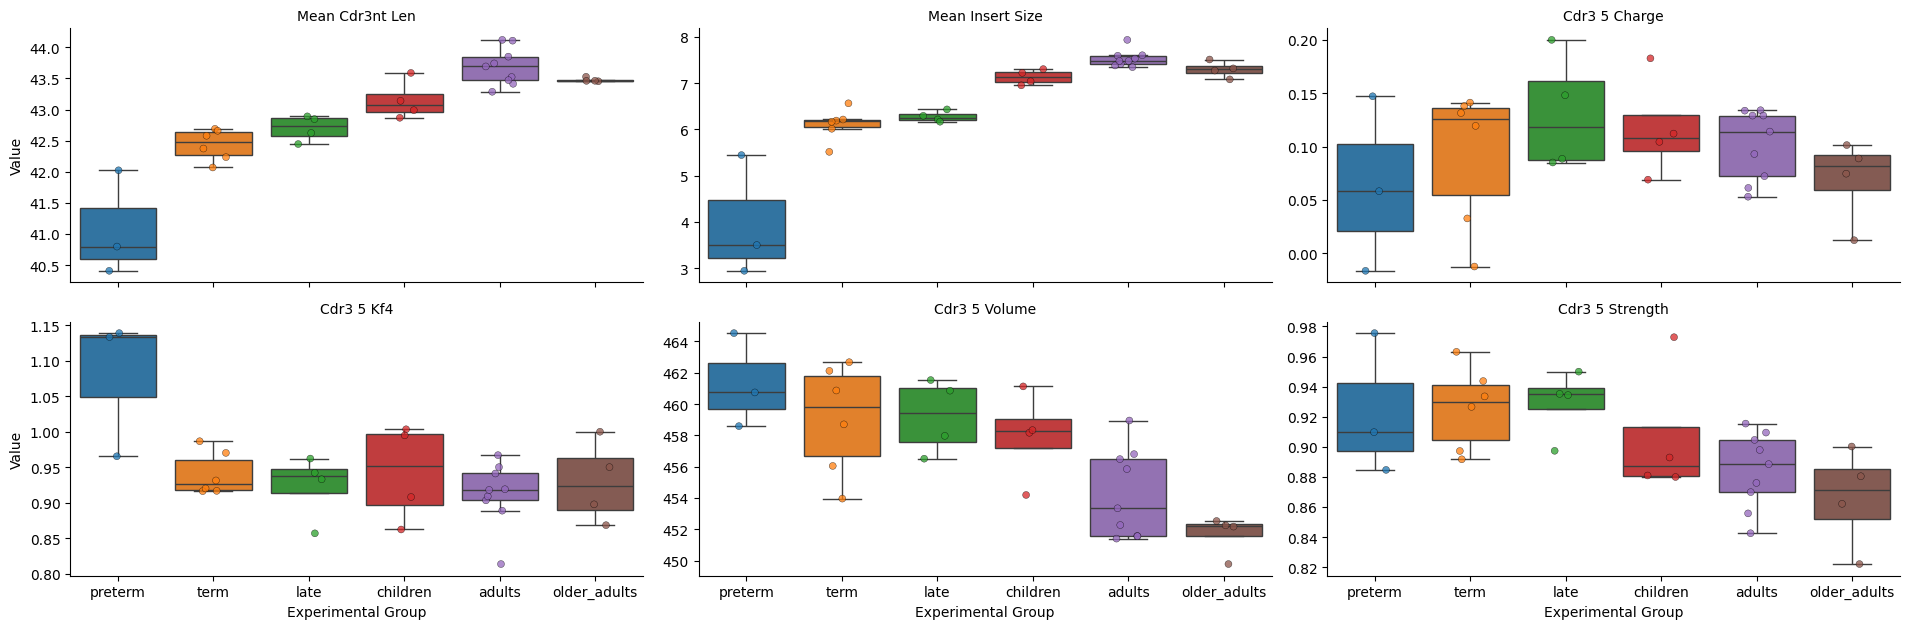

In [ ]:
# Отображаем свойства CDR3 по экспериментальным группам, один образец — одно наблюдение.
rsplot.cdr3aa_stats(cdr3_properties,
                     metadata=metadata,
                     properties=None,
                     group="experimental_group",
                     split=None,
                     palette=None,
                     height=3.2,
                     aspect=2,
                    )

In [ ]:
# Записываем рассчитанные свойства CDR3 в CSV для повторного использования.
cdr3_properties.to_csv(os.path.join(WORKING_DIR, "cdr3_properties.csv"), index=False)

**Распределение длин CDR3.** Здесь сравниваются `preterm` (недоношенные) и `late` (поздний срок гестации) **в одной клеточной популяции**. `seq_type='aa'` задаёт длину в аминокислотах, а `count_by_freq=True` — относительные частоты, а не абсолютное число последовательностей. Ненулевые вставки при рекомбинации могут увеличивать длину CDR3; биологическая гипотеза о возрастном различии связана в том числе с активностью TdT.

На первом графике смотрим профили отдельных образцов, на втором — их группировку.

**Вопрос:** сдвиг распределения отражает изменение средней длины, формы распределения или обоих параметров?

Сдвиг распределения может отражать как изменение средней длины CDR3, так и изменение формы распределения. Для точного вывода нужно сравнить средние значения и характер распределений между группами

## CDR3len distributions

In [ ]:
# Выбираем только nTreg из групп preterm и late для иллюстрации сравнения сроков.
preterm_late_tregs = clonosets_cd4.query("experimental_group in ['preterm', 'late']")
preterm_late_tregs

,sample_id,chain,filename,experimental_group,donor_id,subset,source
0,UCB5_nCD4_TRB_2,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,preterm,UCB5,nCD4,UCB
4,UCB9_nCD4_TRB_2,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,late,UCB9,nCD4,UCB
9,UCB7_nCD4_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,late,UCB7,nCD4,UCB
15,UCB8_nCD4_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,late,UCB8,nCD4,UCB
25,UCB4_nCD4_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,late,UCB4,nCD4,UCB
26,UCB11_nCD4_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,preterm,UCB11,nCD4,UCB
29,UCB1_nCD4_TRB_2,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,preterm,UCB1,nCD4,UCB


In [ ]:
# Получаем частотное распределение длины CDR3 в аминокислотах для каждого образца.
# # zero_fill=True оставляет нулевые частоты для отсутствующих в образце длин.
cdr3_len_distribs = stats.cdr3_length_distributions(
                                                        preterm_late_tregs,
                                                        cl_filter=func_filter,
                                                        cpu=None,
                                                        count_by_freq=True,
                                                        seq_type="aa",
                                                        table="long",
                                                        zero_fill=True,
                                                        verbose=True,
                                                        drop_small_samples=False,
                                                    )
cdr3_len_distribs

Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcCDR3LengthDistribution |##################################################| 7/7 calcultaion(s) processed


,sample_id,chain,cdr3_length,freq
0,UCB11_nCD4_TRB_1,TRB,4,0.000000
1,UCB11_nCD4_TRB_1,TRB,5,0.000007
2,UCB11_nCD4_TRB_1,TRB,6,0.000021
3,UCB11_nCD4_TRB_1,TRB,7,0.000129
4,UCB11_nCD4_TRB_1,TRB,8,0.000371
...,...,...,...,...
156,UCB9_nCD4_TRB_2,TRB,22,0.000053
157,UCB9_nCD4_TRB_2,TRB,23,0.000038
158,UCB9_nCD4_TRB_2,TRB,24,0.000010
159,UCB9_nCD4_TRB_2,TRB,25,0.000010


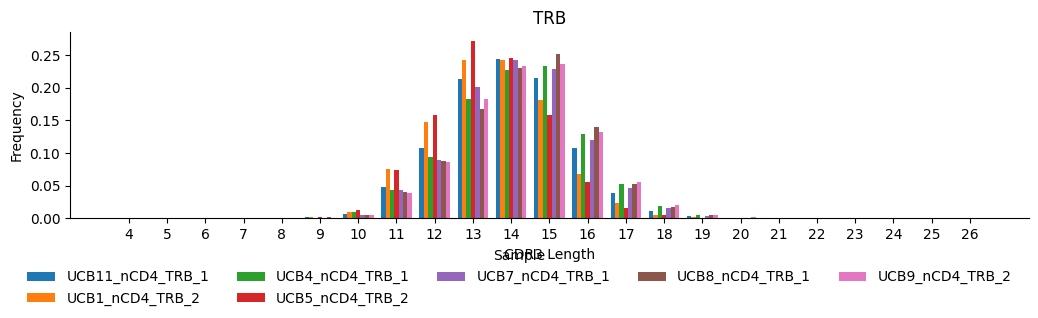

In [ ]:
# Показываем распределения длин для отдельных образцов без разбиения по группам.
rsplot.cdr3_length_distributions(cdr3_len_distribs)

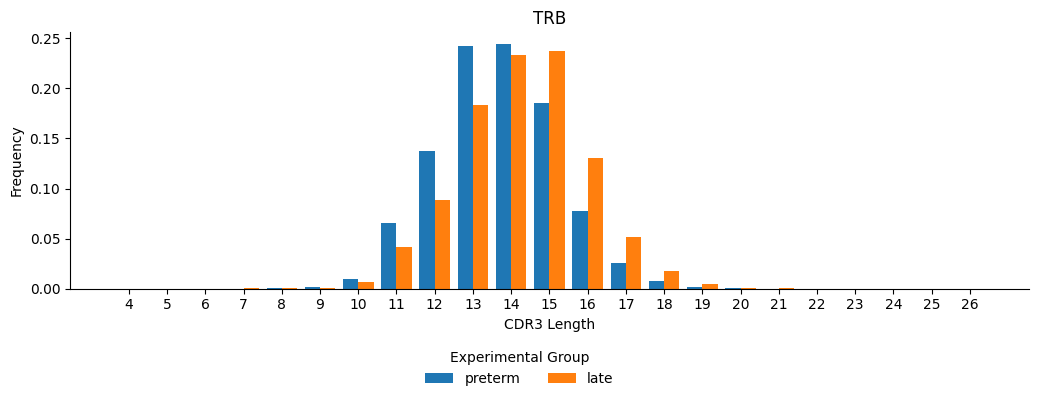

In [ ]:
# Показываем те же распределения, добавляя возрастные/экспериментальные группы.
rsplot.cdr3_length_distributions(cdr3_len_distribs, metadata=metadata, group="experimental_group", height=4)

**Использование сегментов (segment usage).** При сборке TCR используются разные V- и J-сегменты. Их частоты не обязаны быть одинаковыми: влияют особенности рекомбинации, отбора и экспансии клонотипов. Это **описательная метрика**; высокое использование одного сегмента само по себе не доказывает ответ на определённый антиген.

`v_usage`/`j_usage` — таблицы относительного использования сегментов по образцам; тепловая карта, boxplot и barplot показывают одни данные разными способами. `combine_families=True` объединяет родственные V-гены по семействам, поэтому детализация становится грубее.

## Segment usage

### V-usage

In [ ]:
# Считаем частоту использования каждого V-сегмента в каждом функциональном репертуаре.
v_usage = stats.calc_segment_usage(clonosets_cd4, segment="v", cl_filter=func_filter, table="long")
v_usage

Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcSegmentUsage |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,v,usage
0,UCB5_nCD4_TRB_2,TRB,TRBV1,0.000317
1,UCB2_nCD4_TRB_1,TRB,TRBV1,0.000251
2,a7_mnCD4_TRB_1,TRB,TRBV1,0.000180
3,UCB3_nCD4_TRB_1,TRB,TRBV1,0.000657
4,UCB9_nCD4_TRB_2,TRB,TRBV1,0.000533
...,...,...,...,...
1825,UCB4_nCD4_TRB_1,TRB,TRBV7-1,0.000000
1826,UCB11_nCD4_TRB_1,TRB,TRBV7-1,0.000000
1827,o1_mnCD4_TRB_1,TRB,TRBV7-1,0.000000
1828,o6_mnCD4_TRB_2,TRB,TRBV7-1,0.000000


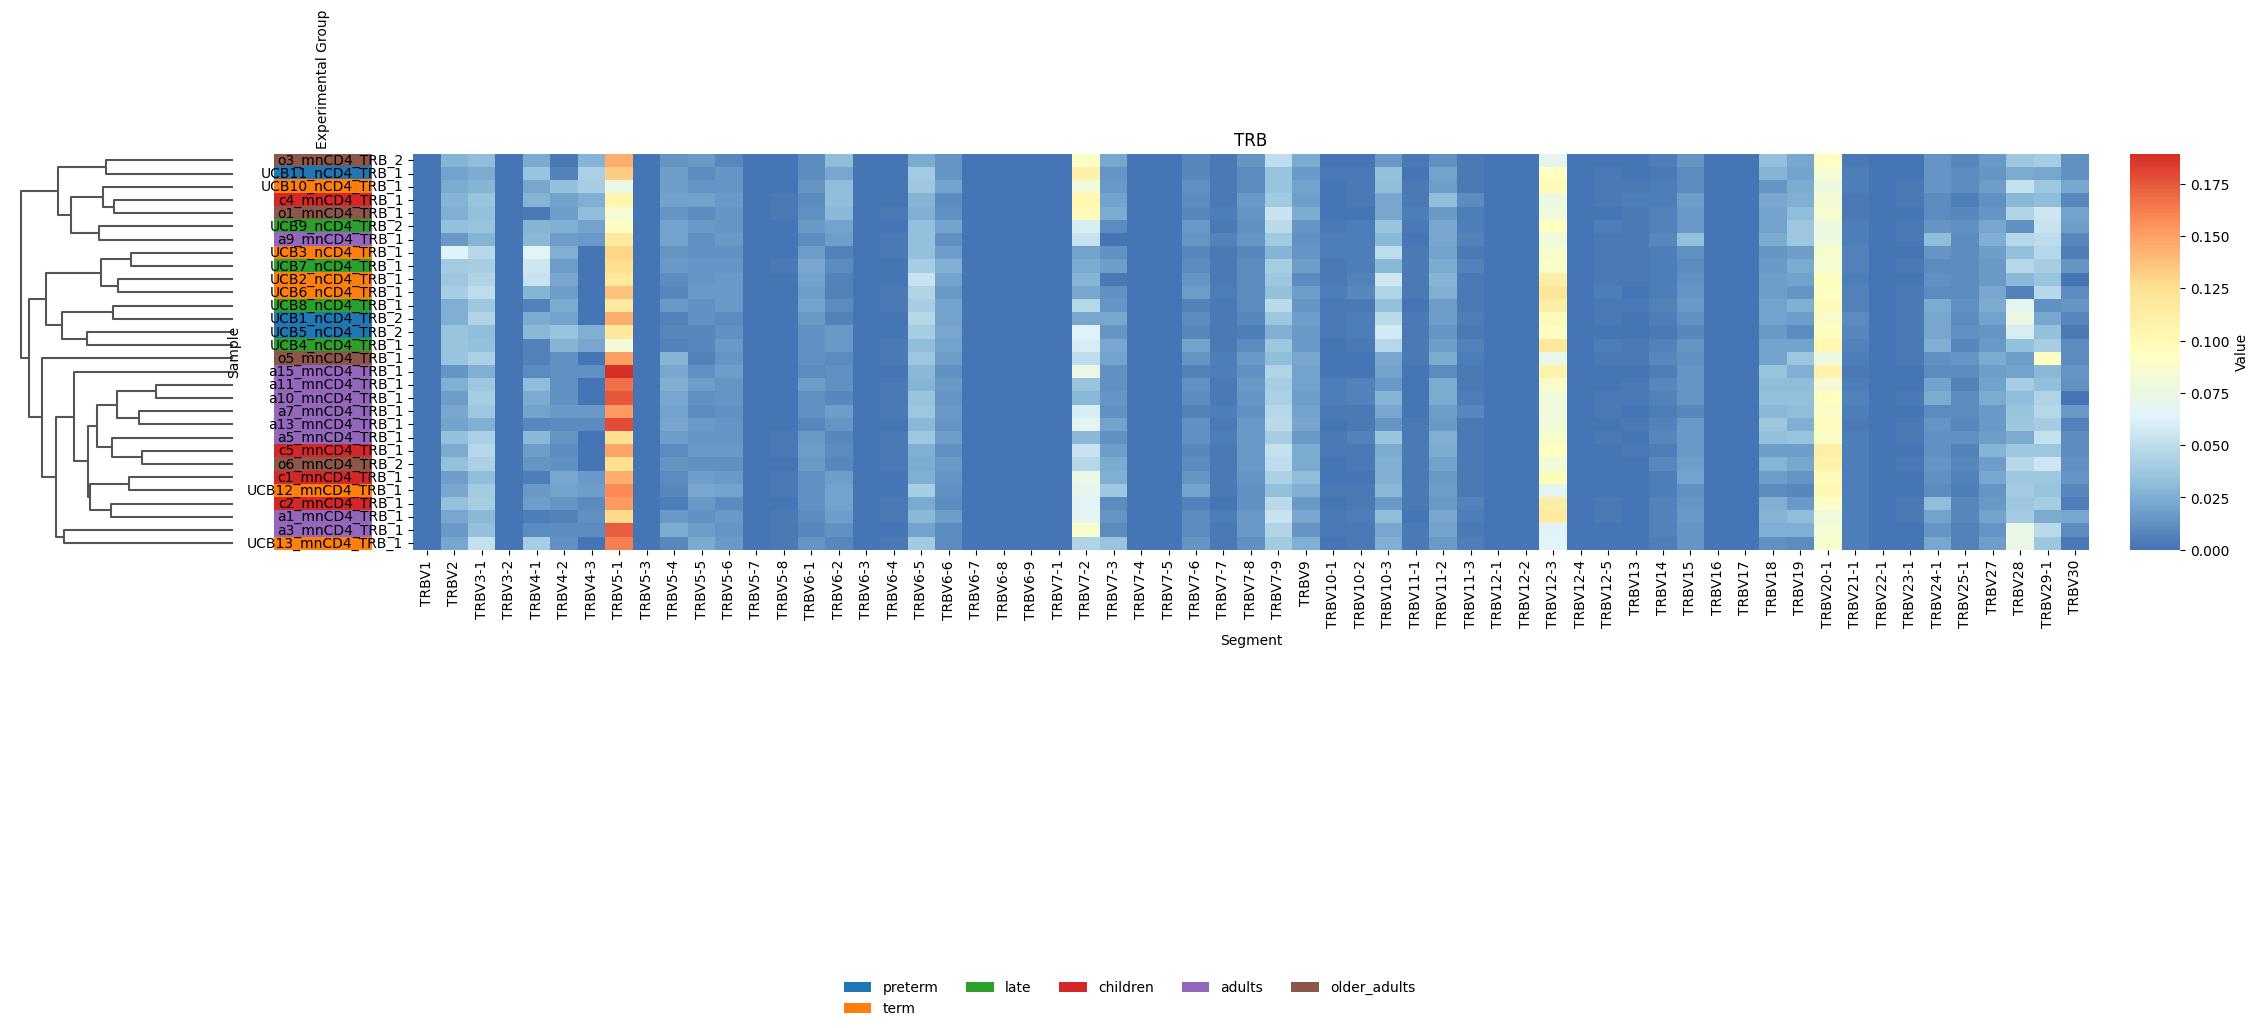

In [ ]:
# Тепловая карта: образцы или группы сопоставляются по профилям использования V.
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="heatmap", height=7)

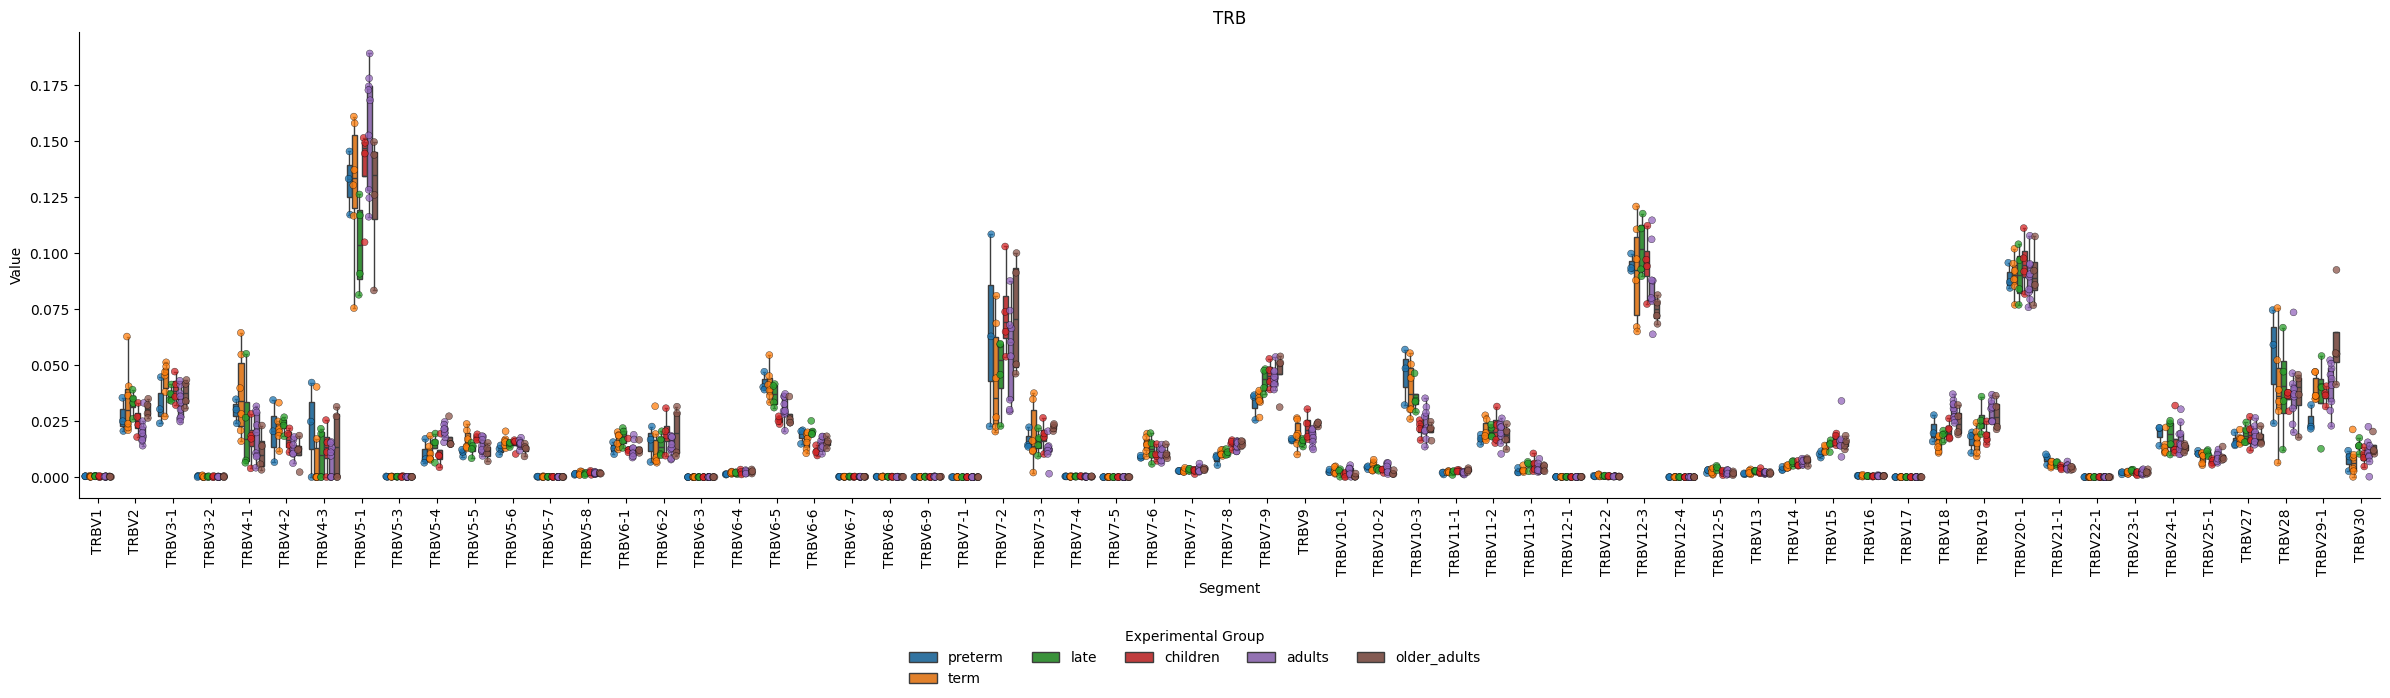

In [ ]:
# Boxplot показывает вариацию использования V-сегментов между образцами групп.
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="boxplot", height=7, )

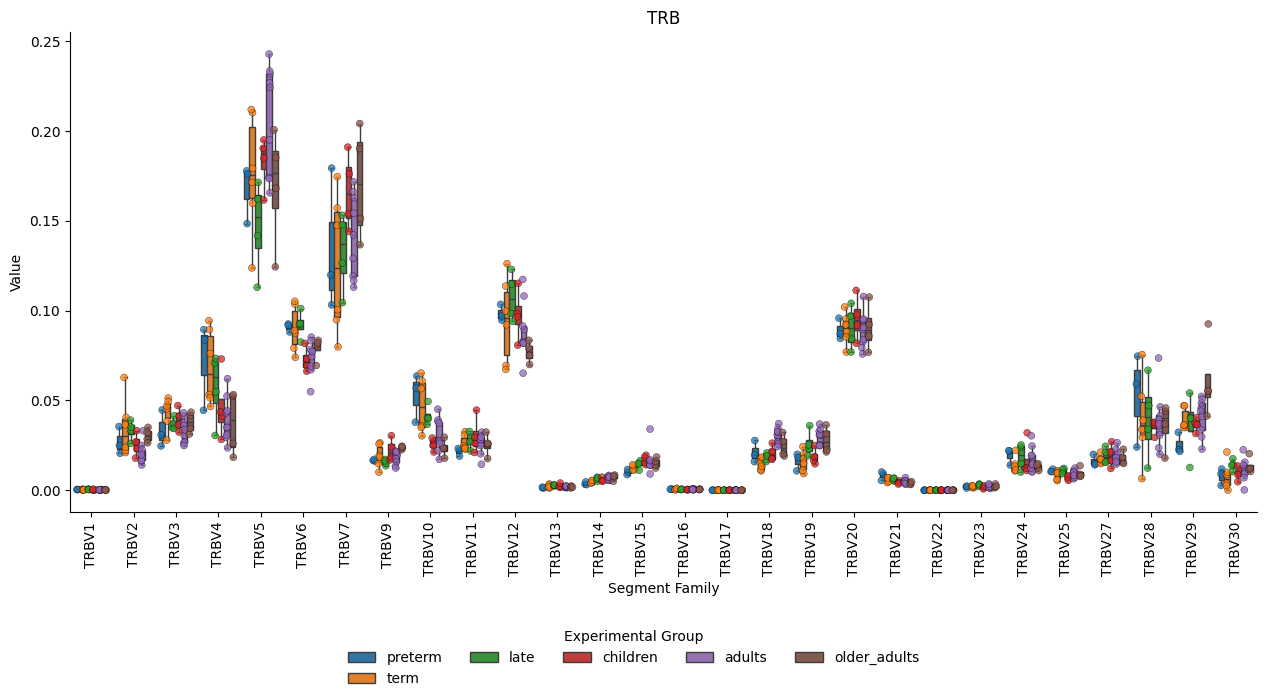

In [ ]:
# Объединяем V-гены по семействам, чтобы увидеть более крупные закономерности.
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="boxplot", height=7, combine_families=True)

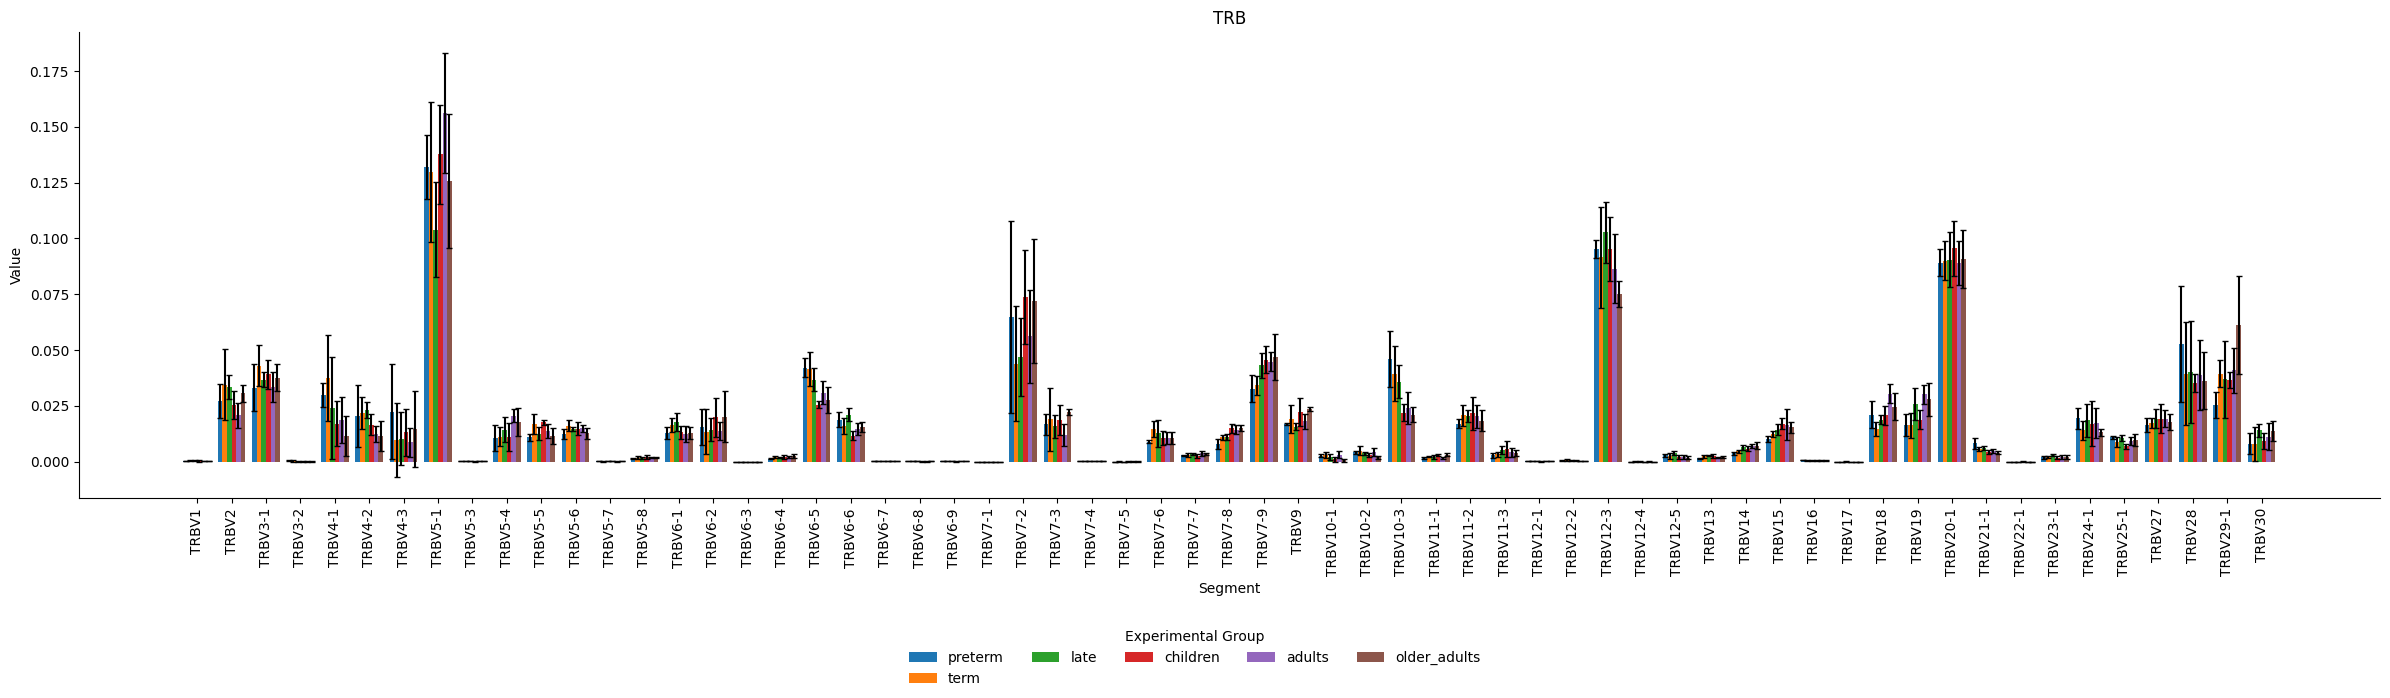

In [ ]:
# Barplot показывает частоты отдельных V-генов.
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="barplot", height=7)

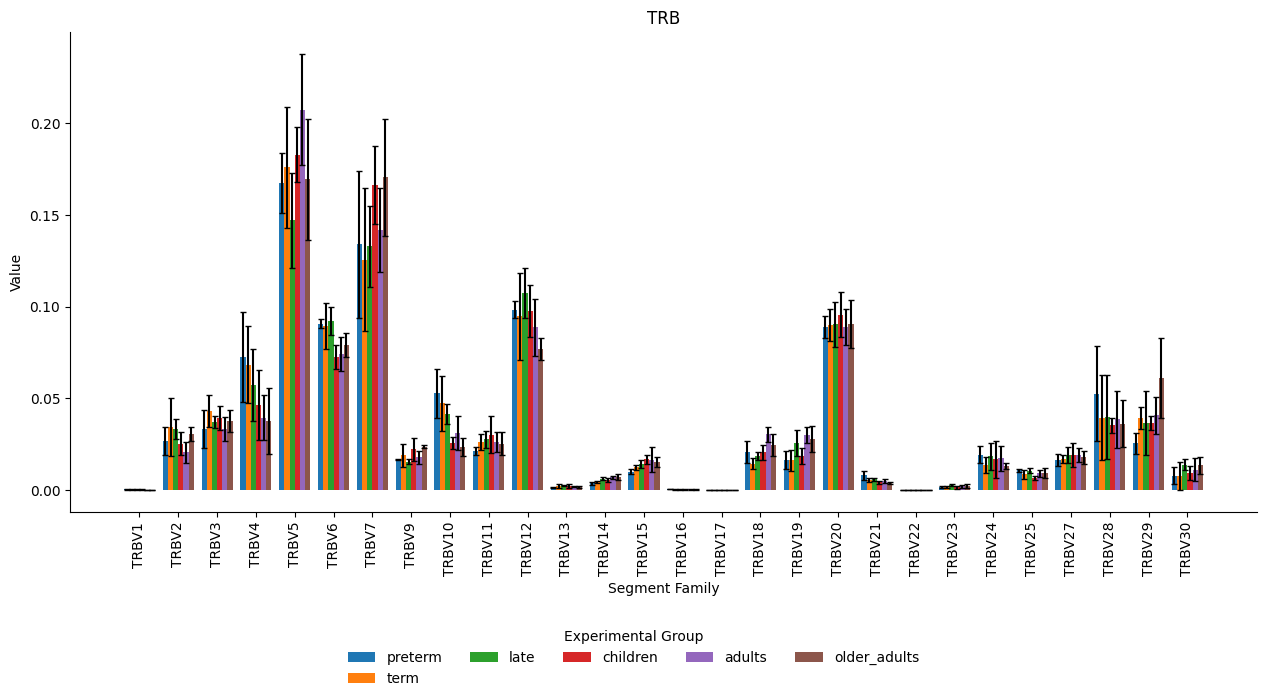

In [ ]:
# Barplot для частот V-семейств вместо отдельных V-генов.
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="barplot", height=7, combine_families=True)

### J-usage

In [ ]:
# Считаем частоты использования J-сегментов вместо V-сегментов.
j_usage = stats.calc_segment_usage(clonosets_cd4, segment="j", cl_filter=func_filter)
j_usage

Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcSegmentUsage |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,j,usage
0,UCB5_nCD4_TRB_2,TRB,TRBJ1-1,0.097860
1,UCB2_nCD4_TRB_1,TRB,TRBJ1-1,0.124051
2,a7_mnCD4_TRB_1,TRB,TRBJ1-1,0.100855
3,UCB3_nCD4_TRB_1,TRB,TRBJ1-1,0.089140
4,UCB9_nCD4_TRB_2,TRB,TRBJ1-1,0.107662
...,...,...,...,...
385,UCB4_nCD4_TRB_1,TRB,TRBJ2-7,0.175978
386,UCB11_nCD4_TRB_1,TRB,TRBJ2-7,0.164483
387,o1_mnCD4_TRB_1,TRB,TRBJ2-7,0.157686
388,o6_mnCD4_TRB_2,TRB,TRBJ2-7,0.052730


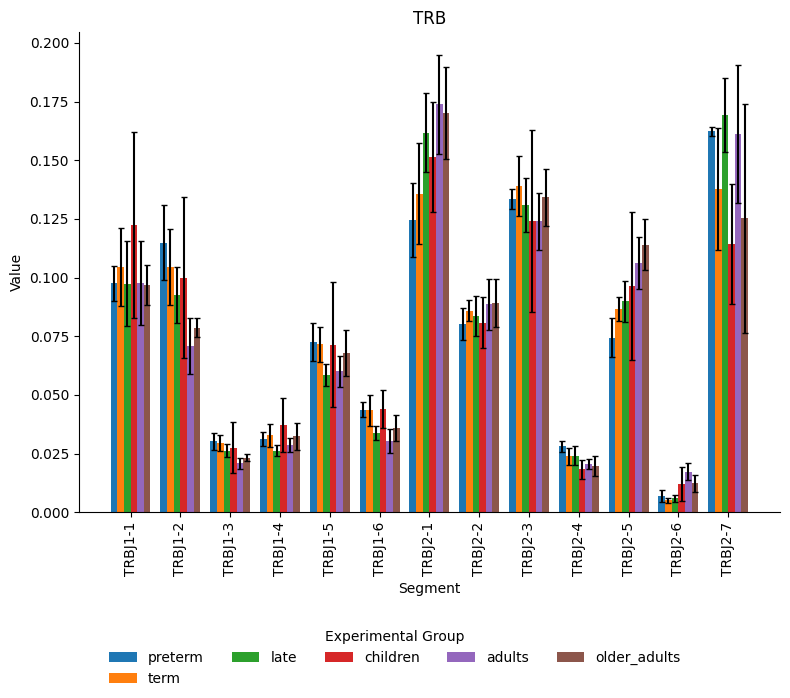

In [ ]:
# Отображаем J-usage по экспериментальным группам.
rsplot.segment_usage(j_usage, metadata=metadata, group="experimental_group", plot_type="barplot", height=7)

**Конвергенция нуклеотидных последовательностей.** Разные CDR3 на уровне ДНК могут кодировать **одинаковую CDR3 на уровне белка** благодаря вырожденности генетического кода и независимым событиям перестройки. Простая мера — число различных CDR3nt, делённое на число различных CDR3aa. При добавлении требований совпадения V или V+J получаются более строгие варианты (`convergence_v`, `convergence_vj`).

Конвергенция зависит также от длины CDR3 и механизма генерации последовательностей; **её увеличение само по себе не доказывает антиген-индуцированную экспансию**. Для сравнения образцов применён одинаковый даунсэмпл.

## Convergence

In [ ]:
# Вычисляем конвергенцию после стандартизации глубины образцов.
# # Функция делает случайные повторы: фиксируем seed для воспроизводимости.
convergence = stats.calc_convergence(clonosets_cd4,
                                     cl_filter=downsample_filter,
                                     seed=42,
                                     cpu=2,
                                     verbose=True
                                    )
convergence

CalcConvergence settings: seed=42, downsample=5000, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 2 cores
CalcClonosetStats |##################################################| 30/30 calcultaion(s) processed
WARNING! Following samples have NaN downsample counts ('umi_func'): UCB5_nCD4_TRB_2, UCB2_nCD4_TRB_1, a7_mnCD4_TRB_1, UCB3_nCD4_TRB_1, UCB9_nCD4_TRB_2, a11_mnCD4_TRB_1, a15_mnCD4_TRB_1, c1_mnCD4_TRB_1, c2_mnCD4_TRB_1, UCB7_nCD4_TRB_1, o5_mnCD4_TRB_1, UCB12_mnCD4_TRB_1, o3_mnCD4_TRB_2, a10_mnCD4_TRB_1, a1_mnCD4_TRB_1, UCB8_nCD4_TRB_1, c5_mnCD4_TRB_1, a5_mnCD4_TRB_1, a3_mnCD4_TRB_1, a9_mnCD4_TRB_1, c4_mnCD4_TRB_1, UCB13_mnCD4_TRB_1, UCB10_nCD4_TRB_1, a13_mnCD4_TRB_1, UCB6_nCD4_TRB_1, UCB4_nCD4_TRB_1, UCB11_nCD4_TRB_1, o1_mnCD4_TRB_1, o6_mnCD4_TRB_2, UCB1_nCD4_TRB_2
These samples will be counted by reads instead
Using 2 cores
CalcConvergence |##################################################| 30/30 calcultaion(s) proc

,sample_id,chain,convergence,convergence_v,convergence_vj
0,UCB5_nCD4_TRB_2,TRB,1.062515,1.010731,1.010731
1,UCB2_nCD4_TRB_1,TRB,1.007475,1.001238,1.001238
2,a7_mnCD4_TRB_1,TRB,1.001353,1.000000,1.000000
3,UCB3_nCD4_TRB_1,TRB,1.009108,1.001680,1.001680
4,UCB9_nCD4_TRB_2,TRB,1.004515,1.001226,1.001226
5,a11_mnCD4_TRB_1,TRB,1.000650,1.000000,1.000000
6,a15_mnCD4_TRB_1,TRB,1.001882,1.000627,1.000627
7,c1_mnCD4_TRB_1,TRB,1.002100,1.000210,1.000210
8,c2_mnCD4_TRB_1,TRB,1.001583,1.000527,1.000527
9,UCB7_nCD4_TRB_1,TRB,1.006794,1.001690,1.001690


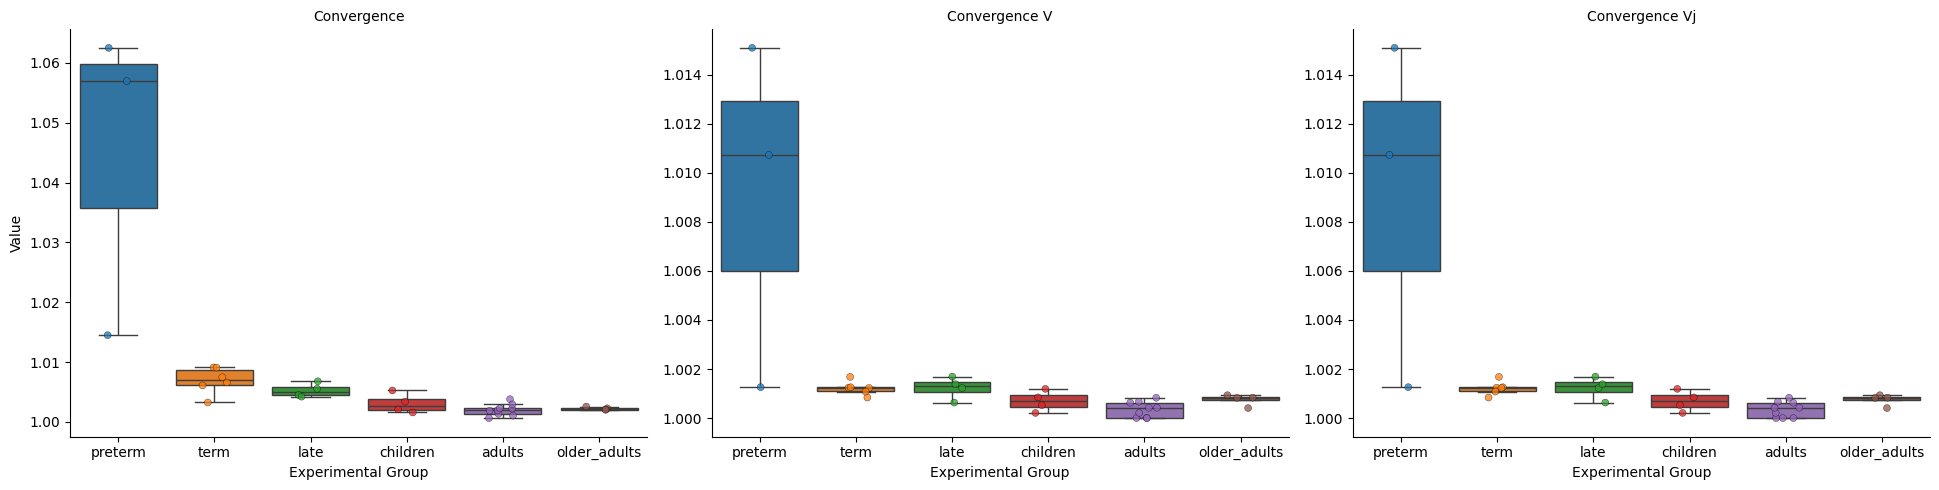

In [ ]:
# Показываем конвергенцию и её варианты по экспериментальным группам.
rsplot.convergence(convergence,
                     metadata=metadata,
                     group="experimental_group",
                     height=5,
                     aspect=1.3
                  )

**Альфа-разнообразие — разнообразие *внутри* одного образца.** Несколько важных метрик:

- **`diversity`** — число обнаруженных клонотипов (богатство); чувствительно к глубине наблюдений.
- **`shannon_wiener`**: $H=-\sum_i p_i\ln p_i$; учитывает и богатство, и равномерность частот.
- **`norm_shannon_wiener`**: нормированная мера равномерности, обычно $H/\ln S$ (при $S>1$); ближе к 1, если частоты более равномерны.
- **`clonality`** — показатель противоположной направленности: больший вклад немногих клонов означает более выраженную клональность.
- Дополнительные метрики в таблице (`chao1`, `simpson`, `inverse_simpson`, `d50`, `gini_coefficient` и др.) по-разному чувствительны к редким и частым клонотипам.

`iterations=3` повторяет случайное субсэмплирование несколько раз; сравнивайте группы по распределению **образцов**, не воспринимая эти повторы как новые независимые биологические реплики. В данном примере настройка `seed` в самой функции и в фильтре могут различаться — ориентируйтесь на параметры расчёта в её логе.

## Diversity stats

In [ ]:
# Считаем несколько индексов альфа-разнообразия на одинаковой глубине.
# # iterations=3 повторяет случайный выбор; это не три биологических образца.
diversity_stats = stats.calc_diversity_stats(clonosets_cd4,
                                             cl_filter=downsample_filter, seed=123, cpu=2,
                                             iterations=3,
                                             drop_small_samples=False,
                                             verbose=True
                                            )
diversity_stats

CalcDiversityStats settings: seed=123, downsample=5000, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 2 cores
CalcClonosetStats |##################################################| 30/30 calcultaion(s) processed
WARNING! Following samples have NaN downsample counts ('umi_func'): UCB5_nCD4_TRB_2, UCB2_nCD4_TRB_1, a7_mnCD4_TRB_1, UCB3_nCD4_TRB_1, UCB9_nCD4_TRB_2, a11_mnCD4_TRB_1, a15_mnCD4_TRB_1, c1_mnCD4_TRB_1, c2_mnCD4_TRB_1, UCB7_nCD4_TRB_1, o5_mnCD4_TRB_1, UCB12_mnCD4_TRB_1, o3_mnCD4_TRB_2, a10_mnCD4_TRB_1, a1_mnCD4_TRB_1, UCB8_nCD4_TRB_1, c5_mnCD4_TRB_1, a5_mnCD4_TRB_1, a3_mnCD4_TRB_1, a9_mnCD4_TRB_1, c4_mnCD4_TRB_1, UCB13_mnCD4_TRB_1, UCB10_nCD4_TRB_1, a13_mnCD4_TRB_1, UCB6_nCD4_TRB_1, UCB4_nCD4_TRB_1, UCB11_nCD4_TRB_1, o1_mnCD4_TRB_1, o6_mnCD4_TRB_2, UCB1_nCD4_TRB_2
These samples will be counted by reads instead
Using 2 cores
CalcDiversityStats |##################################################| 30/30 calcultaion(

,sample_id,chain,diversity,norm_shannon_wiener,clonality,shannon_wiener,chao1,richness,ace,goods_coverage,d50,simpson,inverse_simpson,gini_simpson,berger_parker,gini_coefficient
0,UCB5_nCD4_TRB_2,TRB,4671.0,0.996736,0.003264,8.421554,42149.085938,4671.0,42192.413720,0.1238,0.464783,0.000230,4350.852767,0.999770,0.0008,0.062148
1,UCB2_nCD4_TRB_1,TRB,4867.0,0.998771,0.001229,8.479795,96140.910569,4867.0,95920.115894,0.0522,0.486337,0.000211,4738.438211,0.999789,0.0006,0.025926
2,a7_mnCD4_TRB_1,TRB,4493.0,0.995220,0.004780,8.370072,25421.478261,4493.0,25157.664646,0.1908,0.443579,0.000246,4070.335396,0.999754,0.0008,0.092365
3,UCB3_nCD4_TRB_1,TRB,4796.0,0.998155,0.001845,8.459900,60443.900000,4796.0,60352.972025,0.0802,0.478732,0.000217,4610.844707,0.999783,0.0006,0.039180
4,UCB9_nCD4_TRB_2,TRB,4908.0,0.999184,0.000816,8.491685,130935.391304,4908.0,133369.565217,0.0368,0.490628,0.000207,4822.530864,0.999793,0.0004,0.018055
5,a11_mnCD4_TRB_1,TRB,4639.0,0.996682,0.003318,8.414246,34414.099678,4639.0,34479.981130,0.1392,0.461091,0.000231,4326.756663,0.999769,0.0008,0.067337
6,a15_mnCD4_TRB_1,TRB,4820.0,0.998340,0.001660,8.466449,70671.390244,4820.0,70442.184511,0.0704,0.481328,0.000215,4650.297619,0.999785,0.0006,0.034770
7,c1_mnCD4_TRB_1,TRB,4815.0,0.998249,0.001751,8.464645,71720.347826,4815.0,71141.789030,0.0716,0.480789,0.000216,4634.779385,0.999784,0.0006,0.035751
8,c2_mnCD4_TRB_1,TRB,3956.0,0.989593,0.010407,8.196789,12371.176471,3956.0,12316.055322,0.3670,0.368049,0.000309,3233.316089,0.999691,0.0012,0.175114
9,UCB7_nCD4_TRB_1,TRB,4762.0,0.997860,0.002140,8.450300,50803.461883,4762.0,51142.963161,0.0936,0.475010,0.000220,4550.418639,0.999780,0.0008,0.045376


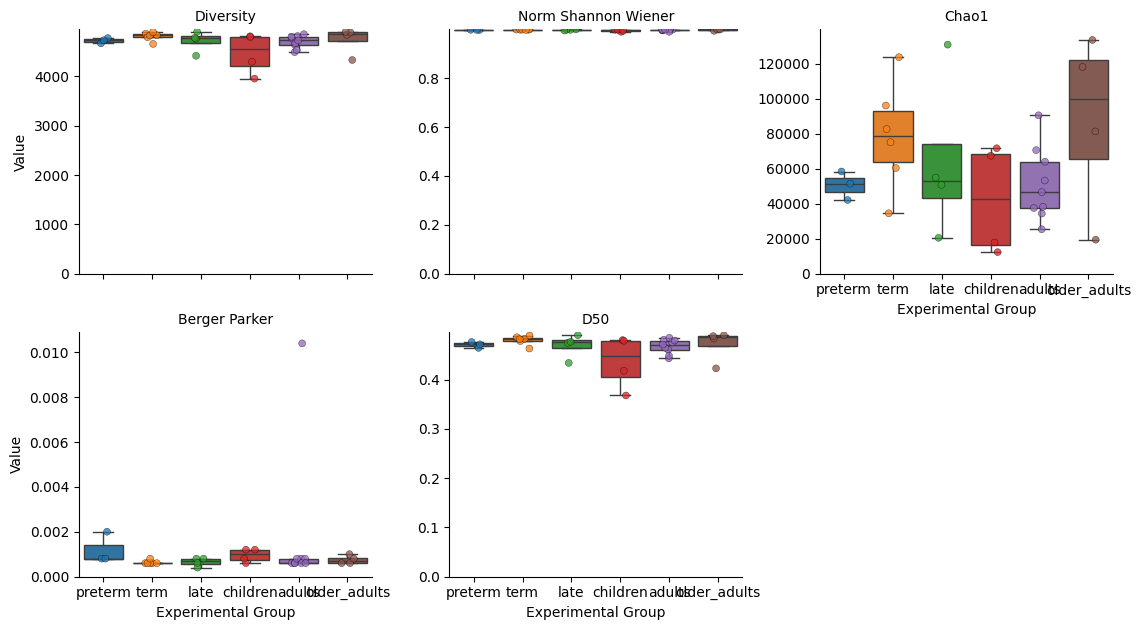

In [ ]:
# Визуализируем богатство, равномерность, клональность и другие индексы.
rsplot.diversity_stats(diversity_stats,
                     metadata=metadata,
                     group="experimental_group"
                    )

CalcDiversityStats settings: seed=123, downsample=4500, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 2 cores
CalcClonosetStats |##################################################| 30/30 calcultaion(s) processed
WARNING! Following samples have NaN downsample counts ('umi_func'): UCB5_nCD4_TRB_2, UCB2_nCD4_TRB_1, a7_mnCD4_TRB_1, UCB3_nCD4_TRB_1, UCB9_nCD4_TRB_2, a11_mnCD4_TRB_1, a15_mnCD4_TRB_1, c1_mnCD4_TRB_1, c2_mnCD4_TRB_1, UCB7_nCD4_TRB_1, o5_mnCD4_TRB_1, UCB12_mnCD4_TRB_1, o3_mnCD4_TRB_2, a10_mnCD4_TRB_1, a1_mnCD4_TRB_1, UCB8_nCD4_TRB_1, c5_mnCD4_TRB_1, a5_mnCD4_TRB_1, a3_mnCD4_TRB_1, a9_mnCD4_TRB_1, c4_mnCD4_TRB_1, UCB13_mnCD4_TRB_1, UCB10_nCD4_TRB_1, a13_mnCD4_TRB_1, UCB6_nCD4_TRB_1, UCB4_nCD4_TRB_1, UCB11_nCD4_TRB_1, o1_mnCD4_TRB_1, o6_mnCD4_TRB_2, UCB1_nCD4_TRB_2
These samples will be counted by reads instead
Using 2 cores
CalcDiversityStats |##################################################| 30/30 calcultaion(

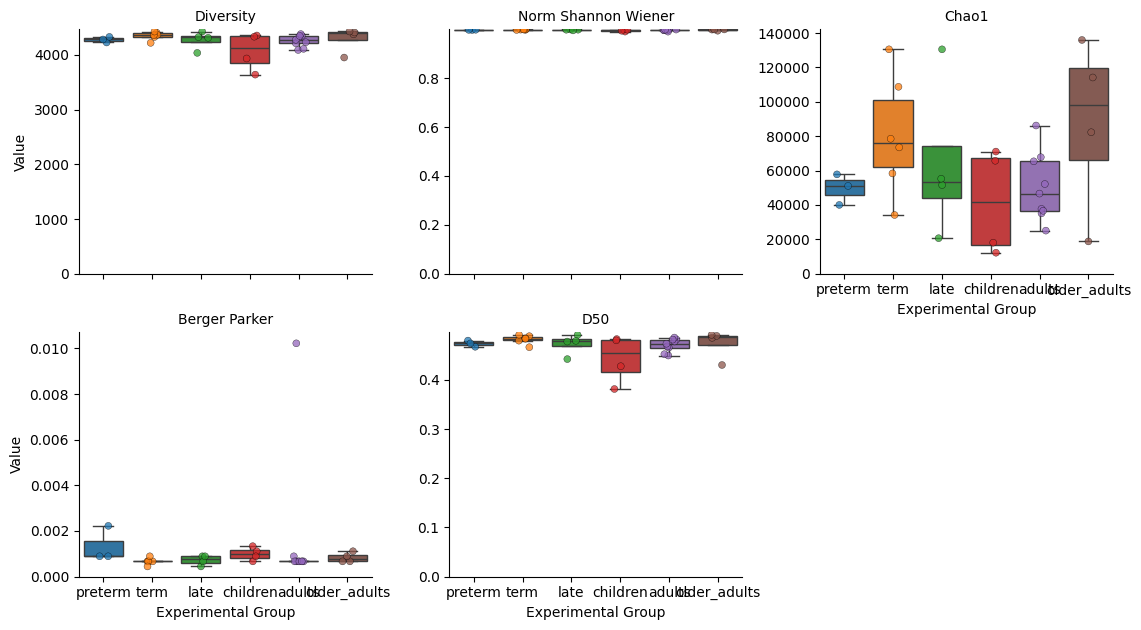

In [ ]:
# Альтернативный фильтр с глубиной 4500
filter_4500 = clf.Filter(
    functionality="f",
    downsample=4500,
    by_umi=True,
    seed=100)

diversity_4500 = stats.calc_diversity_stats(clonosets_cd4,
    cl_filter=filter_4500,
    seed=123,
    cpu=2,
    iterations=3,
    drop_small_samples=False,
    verbose=True
)
rsplot.diversity_stats(diversity_4500,
    metadata=metadata,
    group="experimental_group"
)

**Проверка устойчивости результатов к изменению глубины даунсэмплирования**

Для оценки устойчивости полученных результатов было проведено сравнение показателей альфа-разнообразия при двух значениях глубины даунсэмплирования: 5000 и 4500 наблюдений (остальные параметры оставались неизменными)

При уменьшении глубины до 4500 наблюдений абсолютные значения показателя Diversity несколько снизились, что ожидаемо вследствие уменьшения числа анализируемых наблюдений. При этом общая картина распределения показателей между экспериментальными группами сохранилась

Основные визуальные тенденции альфа-разнообразия nCD4 сохраняются при изменении глубины даунсэмплирования с 5000 до 4500. Это свидетельствует об их относительной устойчивости к небольшому изменению параметра фильтрации. Однако для подтверждения статистической значимости межгрупповых различий необходимы дополнительные статистические тесты

**Rarefaction (кривые разрежения).** Для каждого образца считаем, сколько различных клонотипов обнаружилось бы при разных глубинах выборки. По оси X — `rarefaction_depth` (число наблюдений), по оси Y — ожидаемое обнаруженное богатство `diversity`.

Если кривая выходит на плато, новые наблюдения добавляют мало новых клонотипов. Для TCR-репертуара всего организма плато часто недостижимо на небольшом образце крови. **Не путать** насыщение секвенирования конкретной библиотеки ридами с насыщением биологического репертуара организма. Два графика отличаются только логарифмической/линейной шкалой X.

## Rarefaction

In [ ]:
# Для каждого образца вычисляем богатство при нескольких глубинах наблюдений.
rarefaction_points_ucb = stats.calc_rarefaction_curve(clonosets_cd4, cl_filter=clf.Filter(functionality="f", by_umi=True))
rarefaction_points_ucb

Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcRarefactionPoints |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,rarefaction_depth,diversity
0,UCB10_nCD4_TRB_1,TRB,32,32.000000
1,UCB10_nCD4_TRB_1,TRB,100,100.000000
2,UCB10_nCD4_TRB_1,TRB,316,316.000000
3,UCB10_nCD4_TRB_1,TRB,1000,995.333333
4,UCB10_nCD4_TRB_1,TRB,3162,3123.000000
...,...,...,...,...
239,o6_mnCD4_TRB_2,TRB,3162,3118.333333
240,o6_mnCD4_TRB_2,TRB,10000,9570.000000
241,o6_mnCD4_TRB_2,TRB,31623,27684.000000
242,o6_mnCD4_TRB_2,TRB,100000,69475.333333


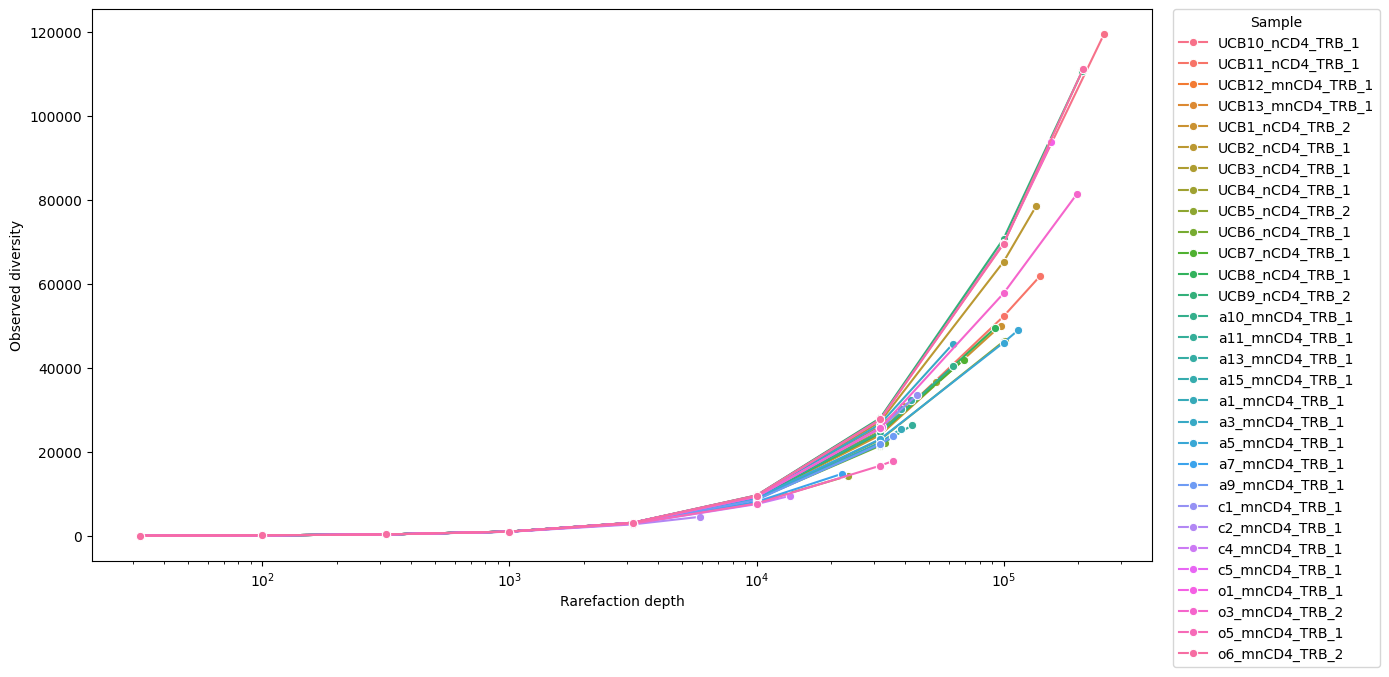

In [ ]:
# Строим rarefaction с логарифмической шкалой глубины для обзора широкого диапазона.
rsplot.rarefaction_curve(rarefaction_points_ucb, log_x=True, aspect=2, height=7)

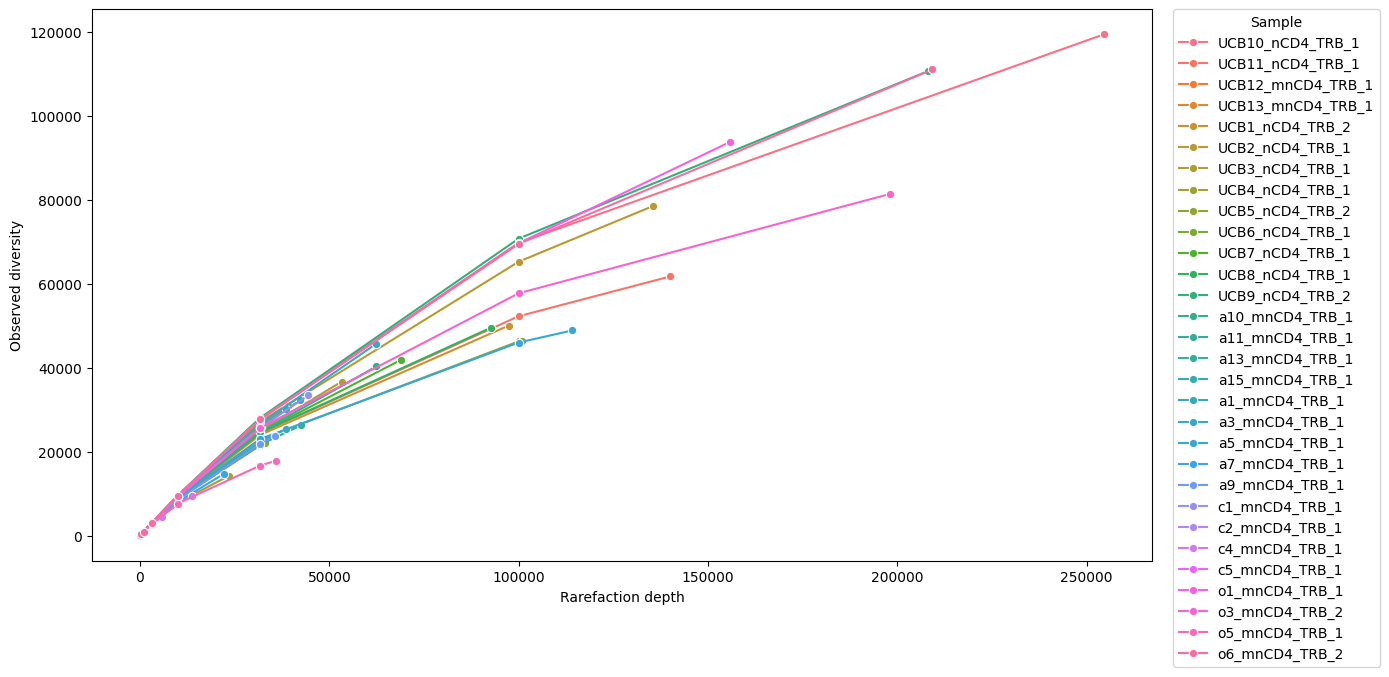

In [ ]:
# Строим ту же кривую с обычной шкалой глубины для оценки формы роста.
rsplot.rarefaction_curve(rarefaction_points_ucb, log_x=False, aspect=2, height=7)

**Бета-разнообразие — сходство *между* образцами.** Мы сравниваем не просто численность клонов, а пересечение определённых последовательностей. В этом ноутбуке совпадение задаётся `overlap_type='aaV'`: **одинаковая аминокислотная CDR3 и один V-ген**. Совпадение только CDR3aa без учёта V — менее строгое правило.

Для двух репертуаров $A$ и $B$ метрика **F2** выражается как $F_2(A,B)=\sum_{i\in A\cap B}\sqrt{p_iq_i}$, где $p_i$, $q_i$ — частоты совпавшего клонотипа в каждом образце. Чем больше F2, тем выше сходство по совпадающим последовательностям с учётом их частот. Диагональ матрицы при одинаковых правилах определения клонотипа равна 1; почти нулевые значения между людьми ожидаемы из-за индивидуального разнообразия TCR.

Это **описательная мера сходства**, а не p-value и не результат теста на различия между экспериментальными группами.

## Beta-diversity

### Main function for beta-diversity

**`beta.metrics`** function calculates a diverse set of Beta-diversity metrics which include (for more detailed explanation refer to **THIS LINK**):

- Number of intersecting clonotypes ('number_of_intersecting_clonotypes')
- Relative diversity ('relative_diversity')
- Pearson correlation ('pearson')
- F1 ('f1') metric - geometric mean of total frequencies of intersecting clonotypes in both samples
- F2 ('f2') metric - sum of geometric means of frequencies of each clonotype in the samples
- ', 'f1', 'f2', 'jaccard', 'jaccard_distance', 'dice', 'dice_distance', 'szymkiewicz_simpson', 'bray_curtis', 'l1', 'total_variation', 'l2', 'morisita_horn', 'jensen_shannon', 'kl_divergence', 'hellinger', 'full_table'

Required input is only the sample_df - DataFrame with the set of repertoires

By default it outputs a dictionary, containing metrics as keys and DataFrames with each metric (or mainly matrices) as values.

In [ ]:
# Считаем попарное сходство клоносетов и таблицы пересечений.
# # aaV означает совпадение CDR3aa И V-гена; значение F2 — сходство, не расстояние.
beta_diversity = beta.metrics(clonosets_cd4,                     # <- clonosets_df - DataFrame with clonosets - sample_id, filename
                              cl_filter=downsample_filter,        # <- you can use a filter to preprocess all the clonosets before intersecting
                              overlap_type="aaV",                     # <- overlap type - is a defenition of similar clonotypes. aaV = similar clonotypes have same CDR3 amino acid sequence and same V gene, and we are not concidering V gene
                              clonosets_df2=None,                     # <- you can pass a second set of clonosets for intersection, otherwise it will intersect all possible pairs with each other
                              cl_filter2=None,                        # <- you can pass a different filter for second set of clonosets, otherwise it will be preprocessed with cl_filter
                              metrics=None,                           # <- you can limit the metrics to a list or a single metric for simplicity of the output
                              cpu=None                                # <- cpus for parallel calculation (=None means - take all avaiable)
                              )

Intersecting clones in clonosets
--------------------------------------------------
Overlap type: aaV
Reading clonosets |##################################################| 30/30 sample(s) processed
Using all available worker processes by default. Set cpu=1 or another integer to change this.
Intersecting clonosets |##################################################| 435/435 pairs processed


In [ ]:
# Смотрим, какие метрики и таблицы вернула функция beta.metrics.
beta_diversity.keys()

dict_keys(['number_of_intersecting_clonotypes', 'relative_diversity', 'pearson', 'f1', 'f2', 'jaccard', 'jaccard_distance', 'dice', 'dice_distance', 'szymkiewicz_simpson', 'bray_curtis', 'l1', 'total_variation', 'l2', 'morisita_horn', 'jensen_shannon', 'kl_divergence', 'hellinger', 'full_table'])

In [ ]:
# Отдельно открываем квадратную матрицу попарного сходства F2.
beta_diversity["f2"]

sample2,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB12_mnCD4_TRB_1,UCB13_mnCD4_TRB_1,UCB1_nCD4_TRB_2,UCB2_nCD4_TRB_1,UCB3_nCD4_TRB_1,UCB4_nCD4_TRB_1,UCB5_nCD4_TRB_2,UCB6_nCD4_TRB_1,...,a7_mnCD4_TRB_1,a9_mnCD4_TRB_1,c1_mnCD4_TRB_1,c2_mnCD4_TRB_1,c4_mnCD4_TRB_1,c5_mnCD4_TRB_1,o1_mnCD4_TRB_1,o3_mnCD4_TRB_2,o5_mnCD4_TRB_1,o6_mnCD4_TRB_2
sample1,,,,,,,,,,,,,,,,,,,,,
UCB10_nCD4_TRB_1,1.000000,0.003249,0.002283,0.002483,0.007453,0.001683,0.003566,0.002847,0.007421,0.001800,...,0.001649,0.001400,0.001400,0.000883,0.001429,0.000600,0.000800,0.001083,0.001200,0.001083
UCB11_nCD4_TRB_1,0.003249,1.000000,0.004931,0.004731,0.015399,0.003283,0.006380,0.002712,0.021920,0.002283,...,0.002083,0.001600,0.001683,0.001912,0.002731,0.001800,0.002546,0.001566,0.001366,0.001083
UCB12_mnCD4_TRB_1,0.002283,0.004931,1.000000,0.003029,0.008336,0.001966,0.003283,0.003083,0.008609,0.001200,...,0.001283,0.000400,0.001083,0.000200,0.000483,0.001683,0.001200,0.000883,0.000800,0.000683
UCB13_mnCD4_TRB_1,0.002483,0.004731,0.003029,1.000000,0.010721,0.003166,0.004131,0.003795,0.014818,0.001283,...,0.002366,0.000400,0.001166,0.000600,0.001931,0.000600,0.001000,0.002395,0.001883,0.000600
UCB1_nCD4_TRB_2,0.007453,0.015399,0.008336,0.010721,1.000000,0.007451,0.016260,0.009555,0.042537,0.006514,...,0.001966,0.001600,0.003456,0.004809,0.001766,0.002166,0.000800,0.002166,0.002449,0.002166
UCB2_nCD4_TRB_1,0.001683,0.003283,0.001966,0.003166,0.007451,1.000000,0.004995,0.004141,0.010110,0.001000,...,0.001566,0.000800,0.001200,0.000283,0.000883,0.001566,0.000800,0.000600,0.000400,0.001000
UCB3_nCD4_TRB_1,0.003566,0.006380,0.003283,0.004131,0.016260,0.004995,1.000000,0.004808,0.021477,0.002400,...,0.001712,0.001146,0.002166,0.001249,0.001659,0.001366,0.001766,0.001200,0.001600,0.000883
UCB4_nCD4_TRB_1,0.002847,0.002712,0.003083,0.003795,0.009555,0.004141,0.004808,1.000000,0.007076,0.000683,...,0.000966,0.001400,0.001166,0.001888,0.000600,0.001483,0.001000,0.000966,0.000200,0.000600
UCB5_nCD4_TRB_2,0.007421,0.021920,0.008609,0.014818,0.042537,0.010110,0.021477,0.007076,1.000000,0.005014,...,0.002759,0.001247,0.003056,0.002478,0.003873,0.001883,0.003166,0.002931,0.003602,0.003083


In [ ]:
print(beta_diversity["full_table"]["pair"].unique())

['UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1'
 'UCB10_nCD4_TRB_1_vs_UCB12_mnCD4_TRB_1'
 'UCB10_nCD4_TRB_1_vs_UCB13_mnCD4_TRB_1'
 'UCB10_nCD4_TRB_1_vs_UCB1_nCD4_TRB_2'
 'UCB10_nCD4_TRB_1_vs_UCB2_nCD4_TRB_1'
 'UCB10_nCD4_TRB_1_vs_UCB3_nCD4_TRB_1'
 'UCB10_nCD4_TRB_1_vs_UCB4_nCD4_TRB_1'
 'UCB10_nCD4_TRB_1_vs_UCB5_nCD4_TRB_2'
 'UCB10_nCD4_TRB_1_vs_UCB6_nCD4_TRB_1'
 'UCB10_nCD4_TRB_1_vs_UCB7_nCD4_TRB_1'
 'UCB10_nCD4_TRB_1_vs_UCB8_nCD4_TRB_1'
 'UCB10_nCD4_TRB_1_vs_UCB9_nCD4_TRB_2'
 'UCB10_nCD4_TRB_1_vs_a10_mnCD4_TRB_1'
 'UCB10_nCD4_TRB_1_vs_a11_mnCD4_TRB_1'
 'UCB10_nCD4_TRB_1_vs_a13_mnCD4_TRB_1'
 'UCB10_nCD4_TRB_1_vs_a15_mnCD4_TRB_1'
 'UCB10_nCD4_TRB_1_vs_a1_mnCD4_TRB_1' 'UCB10_nCD4_TRB_1_vs_a3_mnCD4_TRB_1'
 'UCB10_nCD4_TRB_1_vs_a5_mnCD4_TRB_1' 'UCB10_nCD4_TRB_1_vs_a7_mnCD4_TRB_1'
 'UCB10_nCD4_TRB_1_vs_a9_mnCD4_TRB_1' 'UCB10_nCD4_TRB_1_vs_c1_mnCD4_TRB_1'
 'UCB10_nCD4_TRB_1_vs_c2_mnCD4_TRB_1' 'UCB10_nCD4_TRB_1_vs_c4_mnCD4_TRB_1'
 'UCB10_nCD4_TRB_1_vs_c5_mnCD4_TRB_1' 'UCB10_nCD4_TRB_1_vs_o1_mnCD4_TRB

In [ ]:
# Разбираем пересечение двух конкретных репертуаров на уровне клонотипов.
beta_diversity["full_table"].query("pair == 'UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1'")

,cdr3aa,v,sample1_count,sample2_count,sample1_freq,sample2_freq,sample1,sample2,pair
0,CASSSPEGPKNIQYF,TRBV7-3,1,0,0.0002,0.0000,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1
1,CASSPGLSASKNIQYF,TRBV7-2,1,0,0.0002,0.0000,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1
2,CASSLGWRDQPQHF,TRBV28,1,0,0.0002,0.0000,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1
3,CASSSVQRTDTQYF,TRBV5-1,1,0,0.0002,0.0000,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1
4,CASSYNTGELFF,TRBV5-6,0,1,0.0000,0.0002,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1
...,...,...,...,...,...,...,...,...,...
9623,CASSLIAGASDTQYF,TRBV12-3,1,0,0.0002,0.0000,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1
9624,CASSFRGKRDTQYF,TRBV5-4,1,0,0.0002,0.0000,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1
9625,CASSLRASYGELFF,TRBV12-3,1,0,0.0002,0.0000,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1
9626,CASSLSGSTDTQYF,TRBV5-1,0,1,0.0000,0.0002,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1


**Как читать тепловую карту F2.** Каждая ячейка — результат сравнения **пары образцов**, а не отдельного клонотипа. `ignore_diagonal=True` убирает тривиальные сравнения образца с самим собой; `hclust=True` упорядочивает образцы иерархической кластеризацией. На карте можно искать группы похожих образцов, но визуальный кластер сам по себе не гарантирует статистическую значимость.

### Single metric heatmap plot

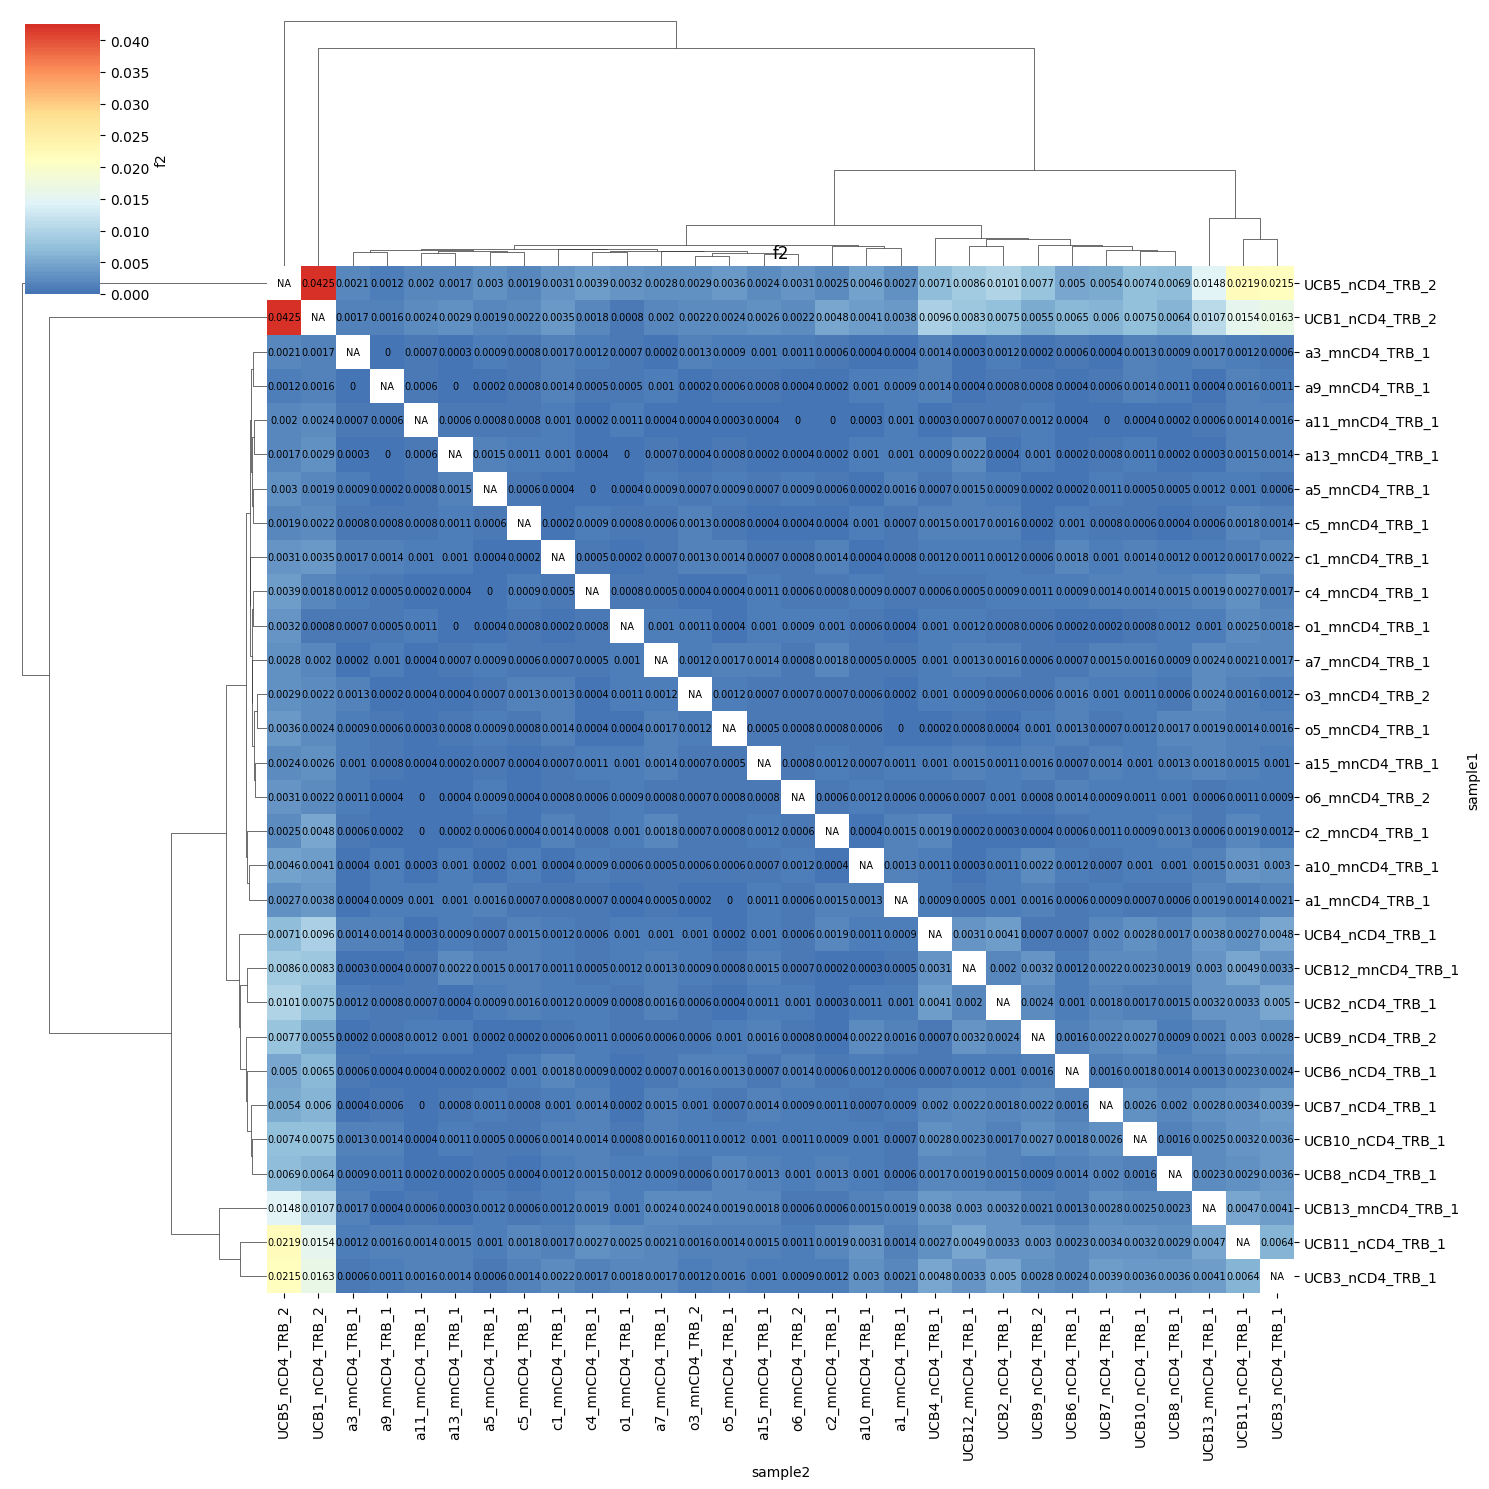

In [ ]:
# Показываем тепловую карту F2, скрываем диагональ, кластеризуем образцы по сходству.
rsplot.beta_metric(beta_diversity,
                   metric="f2",
                   ignore_diagonal=True,
                   hclust=True,
                   log_values=False,
                   height = 15
                  )

**MDS (multidimensional scaling).** Это способ разместить образцы в двумерном пространстве так, чтобы **более близким** в смысле исходной матрицы расстояний объектам соответствовали более близкие точки. Мера F2 — *сходство*, поэтому для методов расстояний её преобразуют (например, в материалах семинара обсуждается $d_{ij}=-\log_{10}(F2_{ij}+\varepsilon)$ с малым $\varepsilon$). Конкретные внутренние вычисления определяет реализация `beta.mds`.

`MDS1` и `MDS2` — **условные координаты**, а не биологические параметры. `centroids=True` показывает центры групп, `dispersion=True` — разброс. Оцениваем, насколько образцы одной группы сближаются; не делаем вывод о значимости без отдельного статистического анализа.

### MDS for metric

In [ ]:
# Преобразуем информацию о попарных отношениях между образцами в координаты MDS.
ucb_treg_mds = beta.mds(beta_diversity)
ucb_treg_mds

,sample_id,MDS1,MDS2
0,UCB10_nCD4_TRB_1,-0.236238,0.006109
1,UCB11_nCD4_TRB_1,0.068681,-0.226389
2,UCB12_mnCD4_TRB_1,0.599247,0.162352
3,UCB13_mnCD4_TRB_1,-0.045092,-0.031517
4,UCB1_nCD4_TRB_2,0.125481,0.102817
5,UCB2_nCD4_TRB_1,0.247642,-0.308571
6,UCB3_nCD4_TRB_1,0.130001,-0.302391
7,UCB4_nCD4_TRB_1,-0.090716,-0.047728
8,UCB5_nCD4_TRB_2,0.046157,-0.019013
9,UCB6_nCD4_TRB_1,-0.370638,0.015724


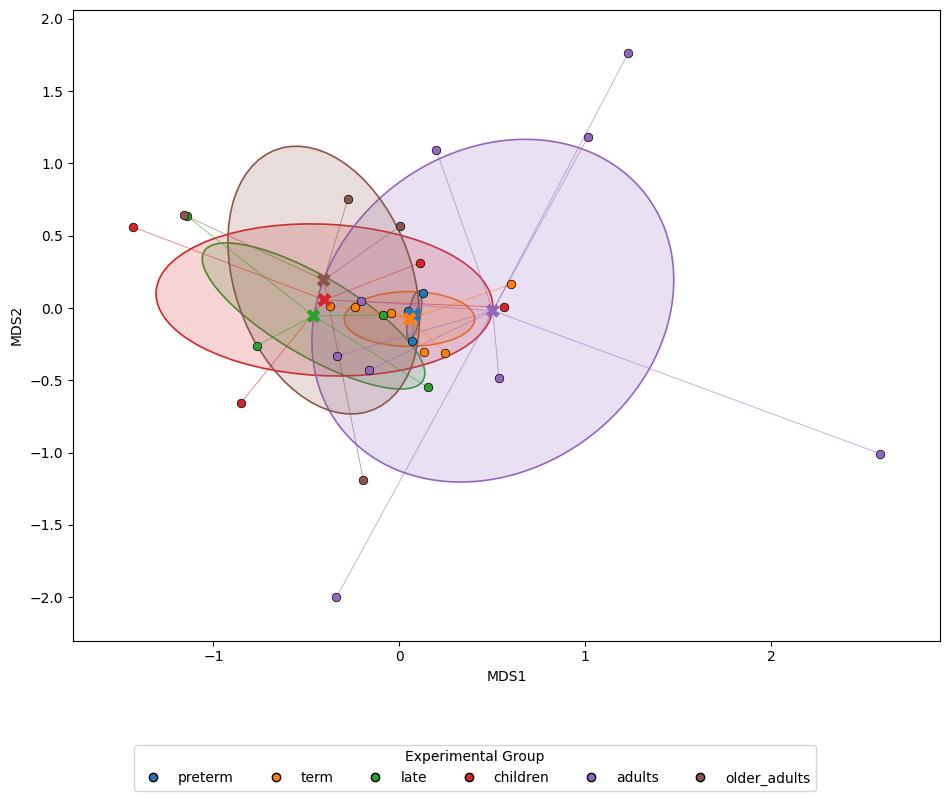

In [ ]:
# Рисуем две координаты MDS с цветом групп, центрами и разбросом.
rsplot.beta_mds(ucb_treg_mds, metadata=metadata, group="experimental_group", centroids=True, dispersion=True, height=8)

**Кластеризация похожих CDR3.** Здесь **объекты — последовательности клонотипов**, а не образцы. Если две последовательности удовлетворяют правилу сходства, между ними можно провести ребро графа. `overlap_type='aaV'` использует аминокислотные CDR3 и V-ген, `mismatches=1` допускает одно несовпадение между сравниваемыми последовательностями.

Важная деталь: в связанном кластере две далёкие вершины могут отличаться **более чем на один символ**, поскольку соединяются цепочкой промежуточных вариантов. Такие кластеры — кандидаты для последующего поиска общей специфичности, но не прямое доказательство распознавания одного антигена. Расчёт и отрисовка могут быть тяжёлыми на больших данных.

## Clustering

### Create clusters

In [ ]:
# Создаём пустой объект, в котором будут храниться клонотипы и связи между ними.
clusters = clustering.Clusters()
clusters

Clusters state:
  State: empty
Clonotypes: not read
Clusters: not created
Metadata: not added
Node Pgen: not calculated
ALICE: not calculated

In [ ]:
# Загружаем отфильтрованные клонотипы всех выбранных образцов в объект кластеризации.
clusters.read_from_clonosets_df(clonosets_cd4, cl_filter=downsample_filter)

Pooled 141117 clonotypes from 30 samples


In [ ]:
# Соединяем близкие по CDR3aa клонотипы с одинаковым V-геном, допуская один mismatch.
clusters.create_clusters(overlap_type='aaV', mismatches=1)

Nodes list created: 141117 nodes
Using all available worker processes by default. Set cpu=1 or another integer to change this.
Find neighbour clonotypes |##################################################| 714/714 tasks processed
found 57900 edges
-----------------------------
NexworkX graph created
Found 7086 clusters (2 or more nodes) and 108313 single nodes. Total: 115399


In [ ]:
# Добавляем к вершинам/последовательностям метаданные экспериментальных групп.
clusters.add_metadata(metadata)

In [ ]:
# Преобразуем граф кластеризации в обычную таблицу для просмотра и фильтрации.
clusters_df = clusters.as_dataframe()
clusters_df

,cluster_no,node_id,cdr3aa,v,j,cdr3nt,sample_id,freq,count,isotype,n_neighbours,experimental_group,donor_id,subset,source
0,0,111366,CASSLGAPGTDTQYF,TRBV5-1,TRBJ2-3,TGCGCCAGCAGCTTAGGGGCTCCTGGCACAGATACGCAGTATTTT,o3_mnCD4_TRB_2,0.0002,1,None,1,older_adults,o3,nCD4,PB
1,0,3755,CASSFSTASYNEQFF,TRBV5-1,TRBJ2-1,TGCGCCAGCAGCTTTTCGACAGCTTCCTACAATGAGCAGTTCTTC,c1_mnCD4_TRB_1,0.0004,2,None,2,children,c1,nCD4,PB
2,0,49451,CASSLGQGSYNEQFF,TRBV5-1,TRBJ2-1,TGCGCCAGCAGCTTGGGACAGGGCTCCTACAATGAGCAGTTCTTC,UCB1_nCD4_TRB_2,0.0002,1,None,29,preterm,UCB1,nCD4,UCB
3,0,81887,CASSLAGGGTDTQYF,TRBV5-1,TRBJ2-3,TGCGCCAGCAGCTTGGCCGGGGGGGGCACAGATACGCAGTATTTT,c1_mnCD4_TRB_1,0.0002,1,None,12,children,c1,nCD4,PB
4,0,129625,CASSRLAGSYNEQFF,TRBV5-1,TRBJ2-1,TGCGCCAGCAGCCGACTAGCGGGGAGCTACAATGAGCAGTTCTTC,c1_mnCD4_TRB_1,0.0002,1,None,4,children,c1,nCD4,PB
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
141112,115394,41280,WGTGGFFYEQYV,TRBV29-1,TRBJ2-7,TGGGGGACAGGGGGTTTCTTCTACGAGCAGTACGTC,o6_mnCD4_TRB_2,0.0002,1,None,0,older_adults,o6,nCD4,PB
141113,115395,61752,WRGGGPYNEQFF,TRBV20-1,TRBJ2-1,TGGAGAGGCGGGGGGCCCTACAATGAGCAGTTCTTC,UCB10_nCD4_TRB_1,0.0002,1,None,0,term,UCB10,nCD4,UCB
141114,115396,5291,WSARQGAAEAFF,TRBV20-1,TRBJ1-1,TGGAGTGCACGACAGGGGGCGGCTGAAGCTTTCTTT,o5_mnCD4_TRB_1,0.0004,2,None,0,older_adults,o5,nCD4,PB
141115,115397,10629,YASSRQGFYQETQYF,TRBV12-3,TRBJ2-5,TATGCCAGCAGCCGCCAGGGGTTCTACCAAGAGACCCAGTACTTC,c4_mnCD4_TRB_1,0.0002,1,None,0,children,c4,nCD4,PB


In [ ]:
# Считаем характеристики кластеров: число вершин, рёбер, размер и консенсус.
cluster_properties = clusters.properties()
cluster_properties

Using all available worker processes by default. Set cpu=1 or another integer to change this.
Calculating cluster properties |##################################################| 115399/115399 clusters processed


,cluster_no,cluster_id,nodes,edges,total_count,diameter,density,eccentricity,concensus_cdr3aa,concensus_cdr3nt,concensus_v,concensus_j
0,0,cluster_0,820,2133,894,44,0.006352,33.014634,CASSLGGGGTNEQFF,TGCGCCAGCAGCTTGGGAGGGGGGGGCACCGATGAGCAGTTCTTC,TRBV5-1,TRBJ2-1
1,1,cluster_1,704,2127,765,25,0.008595,19.321023,CASSLGGGTDTQYF,TGCGCCAGCAGCTTGGGGGGGGGCACAGATACGCAGTACTTC,TRBV5-1,TRBJ2-3
2,2,cluster_2,380,1830,410,15,0.025413,11.418421,CASSLGGDEQYF,TGCGCCAGCAGCTTGGACGGAGATGAGCAGTACTTC,TRBV5-1,TRBJ2-7
3,3,cluster_3,341,991,385,12,0.017095,8.589443,CASSLGGGNTEAFF,TGCGCCAGCAGCTTGGGGGGGGGGAACACTGAAGCTTTCTTT,TRBV5-1,TRBJ1-1
4,4,cluster_4,329,1524,351,17,0.028245,12.170213,CASSLGGTDTQYF,TGCGCCAGCAGCTTGGGGGGCACAGATACGCAGTATTTT,TRBV5-1,TRBJ2-3
...,...,...,...,...,...,...,...,...,...,...,...,...
115394,115394,cluster_115394,1,0,1,0,0.000000,0.000000,WGTGGFFYEQYV,TGGGGGACAGGGGGTTTCTTCTACGAGCAGTACGTC,TRBV29-1,TRBJ2-7
115395,115395,cluster_115395,1,0,1,0,0.000000,0.000000,WRGGGPYNEQFF,TGGAGAGGCGGGGGGCCCTACAATGAGCAGTTCTTC,TRBV20-1,TRBJ2-1
115396,115396,cluster_115396,1,0,2,0,0.000000,0.000000,WSARQGAAEAFF,TGGAGTGCACGACAGGGGGCGGCTGAAGCTTTCTTT,TRBV20-1,TRBJ1-1
115397,115397,cluster_115397,1,0,1,0,0.000000,0.000000,YASSRQGFYQETQYF,TATGCCAGCAGCCGCCAGGGGTTCTACCAAGAGACCCAGTACTTC,TRBV12-3,TRBJ2-5


In [ ]:
# Отбираем кластеры, исключая указанные V- и J-сегменты из демонстрации.
# # Поля concensus_v/concensus_j названы так в выводе библиотеки.
cluster_properties.query("concensus_v != 'TRBV5-1' and concensus_j not in ['TRBJ2-7', 'TRBJ2-3', 'TRBJ1-2']")

,cluster_no,cluster_id,nodes,edges,total_count,diameter,density,eccentricity,concensus_cdr3aa,concensus_cdr3nt,concensus_v,concensus_j
13,13,cluster_13,185,469,195,13,0.027556,10.048649,CSARGGQETQYF,TGCAGTGCTAGAGGGGGGCCAGAGACCCAGTACTTC,TRBV20-1,TRBJ2-5
14,14,cluster_14,171,687,192,10,0.047265,7.081871,CASSLTGNTEAFF,TGTGCCAGCAGTTTAAGGGGGAACACTGAAGCTTTCTTT,TRBV12-3,TRBJ1-1
15,15,cluster_15,145,546,163,12,0.052299,8.834483,CASSLGGNQPQHF,TGTGCCAGCAGTTTAGGGGGCAATCAGCCCCAGCATTTT,TRBV12-3,TRBJ1-5
30,30,cluster_30,99,312,108,9,0.064317,6.747475,CASSLGGGNQPQHF,TGTGCCAGCAGTTTAGCAGGGGGCAATCAGCCCCAGCATTTT,TRBV12-3,TRBJ1-5
32,32,cluster_32,97,406,103,9,0.087199,6.288660,CSARGGNQPQHF,TGCAGTGCTAGAGAGGGCAATCAGCCCCAGCATTTT,TRBV20-1,TRBJ1-5
...,...,...,...,...,...,...,...,...,...,...,...,...
115391,115391,cluster_115391,1,0,1,0,0.000000,0.000000,WASTLYRGHTGELFF,TGGGCCAGCACCCTTTACAGGGGGCACACCGGGGAGCTGTTTTTT,TRBV7-2,TRBJ2-2
115395,115395,cluster_115395,1,0,1,0,0.000000,0.000000,WRGGGPYNEQFF,TGGAGAGGCGGGGGGCCCTACAATGAGCAGTTCTTC,TRBV20-1,TRBJ2-1
115396,115396,cluster_115396,1,0,2,0,0.000000,0.000000,WSARQGAAEAFF,TGGAGTGCACGACAGGGGGCGGCTGAAGCTTTCTTT,TRBV20-1,TRBJ1-1
115397,115397,cluster_115397,1,0,1,0,0.000000,0.000000,YASSRQGFYQETQYF,TATGCCAGCAGCCGCCAGGGGTTCTACCAAGAGACCCAGTACTTC,TRBV12-3,TRBJ2-5


In [ ]:
# Смотрим сводное представление объекта кластеров.
clusters

Clusters state:
  Completed: clonotypes read, clusters created, metadata added
Clonotypes:
    source: clonosets_df
    clonotypes: 141117
    samples: 30
    input_samples: 30
    filter:
      name: default_filter
      functionality: f
      downsample_size: 5000
      top: None
      by_umi: True
      mix_tails: False
      seed: 100
      count_threshold: None
      unweight: False
      recount_fractions: True
      white_list: []
      black_list: []
      pool_by: 
      convert: True
      ignore_small_clonosets: False
      retain_alleles: False
Graph: 141117 nodes and 57900 edges
Clusters: 7086 clusters (2 or more nodes) and 108313 single nodes. Total: 115399
Clustering parameters:
    method: mismatches
    overlap_type: aaV
    mismatches: 1
Metadata columns: experimental_group, donor_id, subset, source
Node Pgen: not calculated
ALICE: not calculated

In [ ]:
print(downsample_filter)

Filter name:	default_filter
Functionality:	only functional clones (no frameshifts and Stops)
Downsample size:	5000
Count by:	 UMI (if exist)
Seed for random:	100



**Визуализация графа.** Вершины представляют последовательности/клонотипы, ребра — заданное выше сходство. Цвет показывает экспериментальную группу; подписи и размеры связаны с числом наблюдений. Здесь выводятся кластеры с номерами от 20 до 29; сами номера — **идентификаторы по результату текущего расчёта**, а не универсальные биологические метки. При другом входном наборе или параметрах их состав может измениться.

### Plot clusters

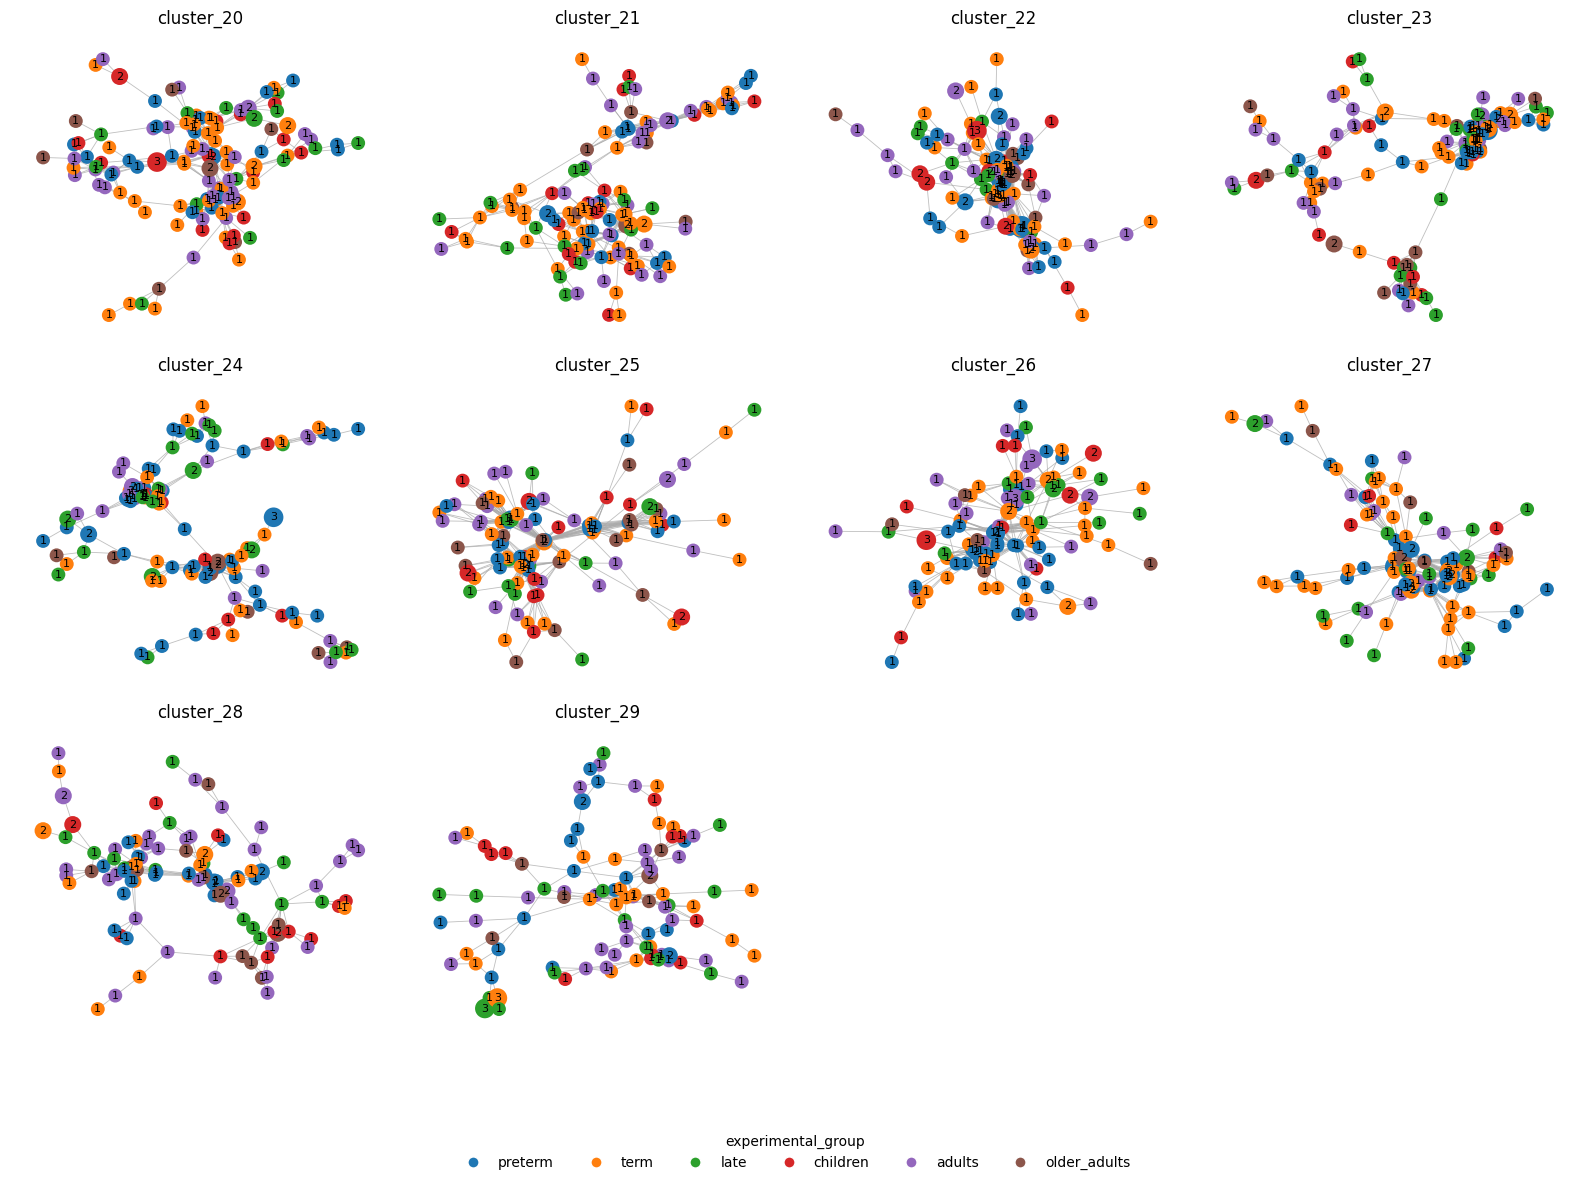

In [ ]:
# Рисуем кластеры 20–29; цвет кодирует группу, размер узла — его count.
clusters.plot_cluster(range(20,30), color="experimental_group", label="count", log_scaled=False, size="count", linear_scale=50)

## Для самостоятельного анализа

В примере выше использовались `nTreg`. Для домашней работы выберите другую отсортированную популяцию (`nCD4` или `nCD8`), проверьте количество доступных образцов и их глубину по `clonoset_stats`, **обоснуйте собственное значение `downsample`** и повторите ключевые метрики. Затем измените один из параметров фильтрации и покажите, какие выводы устойчивы к выбору настроек.

В конце представьте **короткие биологические выводы**, а не только графики: какие группы сравниваются, что означает каждая ось, как интерпретировать изменение показателя и какие есть ограничения (глубина, выборка, различие популяций, случайность субсэмплирования).

## Биологические выводы для nCD4

**1. Исследуемые группы**

Проанализированы репертуары β-цепи TCR (TRB) наивных CD4⁺ T-клеток 30 доноров разных возрастов (по одному образцу на донора): preterm (n = 3), term (n = 6), late (n = 4) - пуповинная кровь; children (n = 4), adults (n = 9), older_adults (n = 4) - периферическая кровь. До выравнивания глубина образцов сильно различалась (медиана функциональных наблюдений от 23 тыс. в children до 177 тыс. в older_adults), поэтому метрики, чувствительные к глубине, считались после даунсэмплирования до 5000 наблюдений на образец

**2. Свойства CDR3**

Анализ CDR3 позволяет охарактеризовать длину и аминокислотные свойства вариабельной области TCR. На графиках по оX - группы, по оY - значение свойства для образца (одна точка = один донор). С возрастом растут средняя длина CDR3 и размер вставки

Older_adults близки к adults (43,5; 7,3). На распределении длин CDR3aa preterm относительно late смещён целиком в сторону коротких последовательностей примерно на долю аминокислоты, форма распределения сходная. Меняется в основном положение распределения, а не его форма. Это согласуется с гипотезой о низкой активности TdT на ранних этапах развития (меньше N-вставок) - сама активность TdT данными не измеряется

**3. Использование V- и J-сегментов**

Доминируют семейства TRBV5, TRBV7, TRBV12, TRBV20 и сегменты TRBJ2-1, TRBJ2-7, TRBJ2-3. Различия между группами небольшие, а разброс внутри групп (особенно в adults) велик. Возможные сдвиги (TRBV4, TRBV10, TRBV12 чаще в группах пуповинной крови, TRBV18/19 слегка чаще у взрослых) статистически не проверялись, поэтому считаем их наблюдением, а не выводом

**4. Конвергенция**

По оX - группы, по оY - отношение числа различных CDR3nt к числу различных CDR3aa (1 означает отсутствие конвергенции, больше 1 — разные нуклеотидные последовательности кодируют один и тот же белок). `convergence_v` и `convergence_vj` дополнительно требуют совпадения V или V+J. У всех трёх образцов preterm значения общей конвергенции выше, чем у любого из остальных 27 образцов, а затем снижаются с возрастом

Возможное объяснение: при коротких вставках последовательность CDR3 сильнее определяется зародышевыми V-, D-, J-сегментами, поэтому независимые перестройки чаще дают один и тот же белок. Внутри preterm конвергенция упорядочена так же, как размер вставки

**5. Альфа-разнообразие и rarefaction**

По оX - группы, по оY - значения индексов при глубине 5000. Значения во всех группах близки к максимуму: число клонотипов 3956–4908 из 5000, нормированный индекс Шеннона примерно равен 1. Но скорее всего это следствие малой глубины, а не признак равномерного репертуара. Кривые разрежения почти линейны и не выходят на плато, т.е. репертуары далеки от насыщения. Оценки Chao1 при такой глубине сильно разбросаны и ненадёжны. Межгрупповые различия альфа-разнообразия небольшие. Наименьшие значения в children принадлежат образцу c2, который одновременно является самым малым по объёму и вероятно отражает ограниченный вход материала, а не биологию группы

**6. Бета-разнообразие**

F2 - мера сходства пары образцов по совпавшим клонотипам (CDR3aa + V) с учётом частот (чем выше, тем больше сходство) Между разными донорами значения низкие, как и ожидается для индивидуальных репертуаров. В старших группах (children, adults, older_adults) F2 как правило не превышает 0,002, в остальных образцах пуповинной крови составляет ≈ 0,002–0,01. Максимальное сходство наблюдается между образцами preterm

На графике MDS (оси MDS1 и MDS2 - условные координаты, а не биологические параметры) preterm образуют компактную группу, а группы по возрасту в целом перекрываются. Большой разброс adults создают несколько выбросов. Чёткого разделения всех групп по возрасту нет. Повышенное сходство репертуаров preterm согласуется с более короткими вставками и повышенной конвергенцией: чем меньше случайных вставок, тем больше шанс, что разные люди независимо получат одинаковую последовательность

**7. Кластеризация**

Кластеризация проводилась по сходству CDR3aa при одинаковом V-гене с допущением одного несовпадения. Из 141 117 клонотипов (30 образцов) в кластеры из двух и более вершин вошли 7 086 кластеров, остальные клонотипы остались одиночными. В показанных кластерах смешаны клонотипы всех групп и разных доноров, а подавляющее большинство вершин имеет count = 1. Это не похоже на группо-специфичные кластеры

**8. Ограничения**

- Малые группы (n = 3–9) и по одному образцу на донора: индивидуальная изменчивость может быть сопоставима с межгрупповыми различиями
- Статистические тесты не проводились, поэтому все различия описаны как тенденции
- Глубина образцов до выравнивания различалась между группами (глубоки preterm и older_adults, неглубоки children)
- Даунсэмплирование до 5000 сохраняет ≈ 10 % наблюдений типичного образца и содержит случайность. При такой глубине индексы разнообразия малоинформативны
- В данных нет отдельного столбца UMI, подсчёт идёт по reads

**9. Итог**

Главная закономерность в нашем наборе nCD4 связана с возрастом: репертуар недоношенных детей отличается короткими CDR3, малым числом N-вставок, повышенной конвергенцией и повышенным сходством между донорами, а с возрастом эти признаки сглаживаются. Это согласуется с гипотезой о низкой активности TdT на ранних этапах развития